# To what extent can people's choices between two cat images be predicted, what limits this predictability, and to what extent can image features improve prediction accuracy?


This report studies 24,896 choices in which a person picked the more appealing of two cat photos. Section 1 explains the motivation and the research questions, and Section 2 explores the data to find a suitable model. Section 3 then tests how predictable the choices are and what limits this, and Section 4 uses the final model to predict the test set. Section 5 covers image features, and Section 6 summarises the findings.

**How to run.** Create a folder named **`data`** next to this notebook and put `train.csv` and `test.csv` in it (in Google Colab: *Files* panel → new folder `data` → upload both files). Then run all cells; this takes about 3–5 minutes on a normal CPU. The notebook writes `test_prediction.csv`, a folder `figures/` and a folder `outputs/`, which should be downloaded before the Colab session ends. All random steps use the seed 2026.

## Setup

In [38]:
# @title
from pathlib import Path
import time, warnings

# train.csv and test.csv must be in a folder called "data" (Colab: /content/data/)
DATA_DIR = Path("data")
missing = [f for f in ["train.csv", "test.csv"] if not (DATA_DIR / f).exists()]
assert not missing, f"Missing {missing} in {DATA_DIR.resolve()}: create a folder 'data' and put train.csv and test.csv in it."
print("data folder:", DATA_DIR.resolve())

data folder: /content/data


In [39]:
# @title
import numpy as np, pandas as pd, scipy.sparse as sp, matplotlib.pyplot as plt, networkx as nx
from scipy import stats, optimize, special
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from IPython.display import display, Markdown
import os, sys
warnings.filterwarnings("ignore")

SEED = 2026
rng = np.random.default_rng(SEED)
rng = np.random.default_rng(SEED)
BLUE, ORANGE, AQUA, GREY, INK = "#2a78d6", "#eb6834", "#1baf7a", "#8a8986", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK, "axes.grid": True,
    "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True, "axes.titleweight": "bold",
    "axes.titlesize": 11, "legend.frameon": False})
pd.set_option("display.precision", 4)
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
OUT_DIR = Path("outputs"); OUT_DIR.mkdir(exist_ok=True)
def save(fig, name):
    fig.tight_layout(); fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight"); plt.show()
def answer(text):
    display(Markdown(f"> **Answer.** {text}"))
T0 = time.time()
def implication(text):
    display(Markdown(f"> **Implication.** {text}"))
def implication(text):
    display(Markdown(f"> **What this means for the analysis.** {text}"))

---
# 1. Introduction

## 1.1 Motivation

We use the **Cat Image Arena dataset**. In each of its 24,896 training rows, one person was shown two cat photos and chose the one they found more appealing; six self-reported characteristics of that person are also recorded. The test set (6,224 rows) has the same columns, but `choice` and `prob_a` are empty, and these are what we fill in. Half of the test rows involve cats that never appear in the training data.

Before building the best predictor, we want to know **how predictable these choices are at all**. Two people often choose differently when shown the same two photos, so no model can be right every time, and without knowing how high accuracy can realistically go we cannot tell whether a model is good or poor. We therefore ask how well the choices can be predicted, what limits this, and whether looking at the photos themselves can improve the predictions.

Because each row is a choice between two items, we use the **Bradley–Terry model**, which gives every item a score and turns the difference in scores into the probability that one item is chosen over the other. Two problems make this hard. One is that people often disagree about the same pair, so part of the error cannot be avoided. The other is that half of the test rows involve cats the model has never seen, so it has no score for them. In this report we measure how much each problem limits prediction, and we build a model that does as well as the data allow.

## 1.2 The data and the test set

Each row records **one person's choice between image A (left) and image B (right)**. Besides the outcome `choice`, the table contains the cat and image labels of both sides, the type of comparison (`within_cat` for two photos of the same cat, `between_cats` for two different cats), and the person's six characteristics. There is no person ID, so one person cannot be followed across rows.

In [40]:
# @title
DEMO = ["gender", "pet_history", "pet_care", "pet_contact", "future_pet", "mbti_ie"]
# encoding="utf-8-sig" removes the byte-order mark at the start of both files
train = pd.read_csv(DATA_DIR / "train.csv", encoding="utf-8-sig", keep_default_na=False, na_values=[""])
test = pd.read_csv(DATA_DIR / "test.csv", encoding="utf-8-sig", keep_default_na=False, na_values=[""])

def images(df): return set(df["a_image"]) | set(df["b_image"])
def cats(df): return set(df["a_cat"]) | set(df["b_cat"])
def unordered(df): return ["||".join(sorted(p)) for p in zip(df["a_image"], df["b_image"])]

glance = pd.DataFrame({
    "train": [len(train), len(set(unordered(train))), len(images(train)), len(cats(train)),
              (train.comparison_type == "within_cat").sum(), train[DEMO].isna().all(axis=1).sum()],
    "test":  [len(test), len(set(unordered(test))), len(images(test)), len(cats(test)),
              (test.comparison_type == "within_cat").sum(), test[DEMO].isna().all(axis=1).sum()],
}, index=["responses (rows)", "distinct image pairs", "distinct images", "distinct cats",
          "within-cat rows", "rows with no annotator info"])
display(glance)
print("columns:", list(train.columns))

,train,test
responses (rows),24896,6224
distinct image pairs,8049,2029
distinct images,1296,1389
distinct cats,237,284
within-cat rows,3003,999
rows with no annotator info,508,130


columns: ['train_row_id', 'a_cat', 'b_cat', 'a_image', 'b_image', 'choice', 'comparison_type', 'gender', 'pet_history', 'pet_care', 'pet_contact', 'future_pet', 'mbti_ie']


comparison_type,between_cats,within_cat,total,share
stratum,,,,
both cats seen,2743,369,3112,0.50
one new cat,1556,0,1556,0.25
two new cats\n(or a new cat vs itself),926,630,1556,0.25


seen cats <=> seen images in every test row: True
test image pairs that also appear in train: 0
new cats in test: 47   new images in test: 262


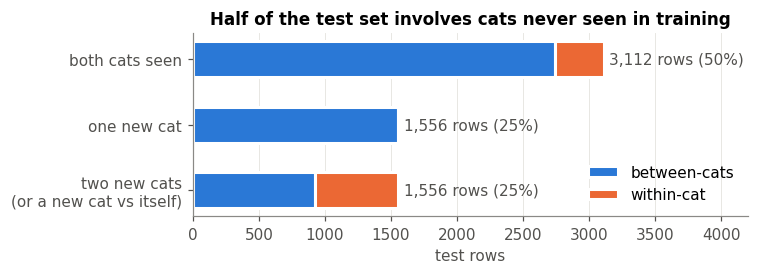

In [41]:
# @title
train_cats, train_imgs = cats(train), images(train)
test["n_seen_cats"] = test["a_cat"].isin(train_cats).astype(int) + test["b_cat"].isin(train_cats).astype(int)
test["n_seen_imgs"] = test["a_image"].isin(train_imgs).astype(int) + test["b_image"].isin(train_imgs).astype(int)
STRATA = {2: "both cats seen", 1: "one new cat", 0: "two new cats\n(or a new cat vs itself)"}
test["stratum"] = test["n_seen_cats"].map(STRATA)

strata = pd.crosstab(test["stratum"], test["comparison_type"]).reindex(list(STRATA.values()))
strata["total"] = strata.sum(axis=1); strata["share"] = strata["total"] / len(test)
display(strata)
print("seen cats <=> seen images in every test row:", bool((test.n_seen_cats == test.n_seen_imgs).all()))
print("test image pairs that also appear in train:", len(set(unordered(test)) & set(unordered(train))))
print("new cats in test:", len(cats(test) - train_cats), "  new images in test:", len(images(test) - train_imgs))

fig, ax = plt.subplots(figsize=(7, 2.6))
left = np.zeros(len(strata))
for col, colr in [("between_cats", BLUE), ("within_cat", ORANGE)]:
    ax.barh(range(len(strata)), strata[col], left=left, color=colr, height=0.55, label=col.replace("_", "-"),
            edgecolor="white", linewidth=2)
    left += strata[col].to_numpy()
for i, (tot, sh) in enumerate(zip(strata["total"], strata["share"])):
    ax.text(tot + 40, i, f"{tot:,} rows ({sh:.0%})", va="center", color=INK)
ax.set_yticks(range(len(strata)), strata.index); ax.invert_yaxis()
ax.set_xlim(0, strata["total"].max() * 1.35); ax.set_xlabel("test rows"); ax.grid(axis="y", visible=False)
ax.set_title("Half of the test set involves cats never seen in training")
ax.legend(loc="lower right")
save(fig, "1_3_test_strata")

**Half of the test set involves cats never seen in training, and none of the 2,029 test pairs was compared in training.** A model that only remembers which cat won in training can therefore say nothing about a new cat, so predictability has to be measured separately for seen and new cats.

## 1.3 Research questions

The main research question is divided into four sub-questions:

1. **How predictable are the choices?** Using only the training table (cat and image labels, the side of each image, and the person's characteristics), how accurately can the test choices be predicted, and how close is this to the best possible?
2. **How much do people agree?** How consistent are different people when they choose between the same two images, and how much of the prediction error does their disagreement explain?
3. **Do all people rank the cats in the same way?** Can one shared appeal score for each cat and photo explain everyone's choices, or do people with different characteristics prefer different cats?
4. **Can image features help?** For cats never seen in training, can features of the photos predict which image will be chosen?

The first question measures predictability, while the next two ask whether it is limited by disagreement between people or by the assumption that everyone ranks the cats in the same way. The fourth asks whether it is limited by missing information about what the photos show, such as whether the cat looks at the camera.

---
# 2. Exploratory Analysis

This section first looks at the training and test data together and then studies the training data in detail, so that each finding points to one part of the model used in Section 3.

## 2.1 Data quality and the test set

We first check that every field takes only the values listed in the README and that the structure is consistent, and then compare the two files.

In [42]:
# @title
ALLOWED = {
    "choice": {"A", "B"}, "comparison_type": {"within_cat", "between_cats"}, "gender": {"man", "woman"},
    "pet_history": {"current", "past", "never"}, "pet_care": {"never", "occasionally", "past_regular", "current_regular"},
    "pet_contact": {"never", "rarely", "sometimes", "often", "daily"}, "future_pet": {"yes", "no", "unsure"},
    "mbti_ie": {"I", "E", "unknown"},
}
def run_checks(df, id_col, has_choice):
    same_cat = df.a_cat == df.b_cat
    n_missing = df[DEMO].isna().sum(axis=1)
    out = {
        "rows": len(df),
        "IDs unique": df[id_col].is_unique,
        "unexpected category values": sum(len(set(df[c].dropna()) - ok) for c, ok in ALLOWED.items()
                                          if c in df and (has_choice or c != "choice")),
        "comparison_type inconsistent with cat IDs": int(((df.comparison_type == "within_cat") != same_cat).sum()),
        "same image on both sides": int((df.a_image == df.b_image).sum()),
        "image path not in its cat folder": int(sum(not i.startswith(c + "/") for i, c in zip(df.a_image, df.a_cat))
                                                + sum(not i.startswith(c + "/") for i, c in zip(df.b_image, df.b_cat))),
        "rows with ALL six annotator fields missing": int((n_missing == 6).sum()),
        "rows with SOME (1-5) annotator fields missing": int(((n_missing > 0) & (n_missing < 6)).sum()),
    }
    if not has_choice:
        out["choice / prob_a already filled"] = int(df["choice"].notna().sum() + df["prob_a"].notna().sum())
    return pd.Series(out)

display(pd.concat({"train": run_checks(train, "train_row_id", True),
                   "test": run_checks(test, "test_row_id", False)}, axis=1))

,train,test
rows,24896,6224
IDs unique,True,True
unexpected category values,0,0
comparison_type inconsistent with cat IDs,0,0
same image on both sides,0,0
image path not in its cat folder,0,0
rows with ALL six annotator fields missing,508,130
rows with SOME (1-5) annotator fields missing,0,0
choice / prob_a already filled,NaN,0


In [43]:
# @title
def construct(df):
    df = df.copy()
    df[DEMO] = df[DEMO].fillna("missing")
    df["demo_missing"] = df["gender"].eq("missing")
    df["pair_u"] = unordered(df)
    df["pair_o"] = df["a_image"] + "||" + df["b_image"]
    df["a_idx"] = df["a_image"].str.extract(r"_(\d+)\.jpg$")[0].astype(int)
    df["b_idx"] = df["b_image"].str.extract(r"_(\d+)\.jpg$")[0].astype(int)
    df["profile"] = df[DEMO].agg("|".join, axis=1)
    return df

train, test = construct(train), construct(test)
train["y"] = (train["choice"] == "A").astype(int)
train["winner_img"] = np.where(train.y == 1, train.a_image, train.b_image)
train["loser_img"] = np.where(train.y == 1, train.b_image, train.a_image)
train["winner_cat"] = np.where(train.y == 1, train.a_cat, train.b_cat)
train["loser_cat"] = np.where(train.y == 1, train.b_cat, train.a_cat)

# "long" format: one row per image appearance (used for win rates)
long = pd.concat([
    pd.DataFrame({"row": train.index, "img": train.a_image, "cat": train.a_cat, "idx": train.a_idx, "side": "A",
                  "won": train.y, "type": train.comparison_type, "pair_u": train.pair_u}),
    pd.DataFrame({"row": train.index, "img": train.b_image, "cat": train.b_cat, "idx": train.b_idx, "side": "B",
                  "won": 1 - train.y, "type": train.comparison_type, "pair_u": train.pair_u}),
], ignore_index=True)
train[["y", "pair_u", "winner_img", "a_idx", "profile"]].head(3)

,y,pair_u,winner_img,a_idx,profile
0,1,cat_002145/cat_002145_0003.jpg||cat_002145/cat...,cat_002145/cat_002145_0006.jpg,6,woman|current|current_regular|sometimes|yes|I
1,1,cat_000751/cat_000751_0005.jpg||cat_005017/cat...,cat_000751/cat_000751_0005.jpg,5,man|never|never|rarely|yes|I
2,1,cat_001019/cat_001019_0002.jpg||cat_001019/cat...,cat_001019/cat_001019_0002.jpg,2,man|current|occasionally|rarely|unsure|I


In [44]:
# @title
def tvd(a, b):
    p, q = a.value_counts(normalize=True), b.value_counts(normalize=True)
    return 0.5 * p.subtract(q, fill_value=0).abs().sum()

shift = pd.DataFrame({
    "train": [f"{(train.comparison_type == 'within_cat').mean():.1%}", f"{train.demo_missing.mean():.1%}",
              train.profile.nunique(), "-"],
    "test": [f"{(test.comparison_type == 'within_cat').mean():.1%}", f"{test.demo_missing.mean():.1%}",
             test.profile.nunique(), f"{test.profile.isin(set(train.profile)).mean():.0%}"],
}, index=["share of within-cat rows", "share with missing annotator info", "distinct annotator profiles",
          "test rows whose profile occurs in train"])
display(shift)

display(pd.Series({c: tvd(train[c], test[c]) for c in DEMO}, name="difference in distribution, train vs test (share of rows)")
        .to_frame().T.round(3))

w_test = test[test.comparison_type == "within_cat"]
print(f"within-cat test rows: {len(w_test)}; of these, rows showing a NEW cat: "
      f"{(w_test.n_seen_cats == 0).sum()} ({(w_test.n_seen_cats == 0).mean():.0%})")
print("photo numbers: train max", int(long.idx.max()), "| test max", int(max(test.a_idx.max(), test.b_idx.max())))

,train,test
share of within-cat rows,12.1%,16.1%
share with missing annotator info,2.0%,2.1%
distinct annotator profiles,70,70
test rows whose profile occurs in train,-,100%


,gender,pet_history,pet_care,pet_contact,future_pet,mbti_ie
"difference in distribution, train vs test (share of rows)",0.001,0.002,0.008,0.009,0.005,0.006


within-cat test rows: 999; of these, rows showing a NEW cat: 630 (63%)
photo numbers: train max 18 | test max 16


**All checks pass.** The only issue is that **508 training rows and 130 test rows have all six characteristics of the person blank**. Since the test set has such rows too, we keep them and treat the blank as its own category, `missing`. Moreover, the people are the same in both files: every characteristic differs by less than 1 percentage point, and **every test profile (combination of the six characteristics) also appears in training**. The mix of comparisons, however, differs, because within-cat rows make up 16% of the test set against 12% of training.

These results mean that **validation must copy the structure of the test set instead of splitting the rows at random**. We therefore use **pair cross-validation (pair-CV)**, which splits the data by image pair, for pairs of seen cats, and **cat cross-validation (cat-CV)**, which splits the data by cat, for new cats (§3.1).

## 2.2 Dependence between rows and the left-side effect

Standard errors and cross-validation assume independent rows, yet the same pairs, images and cats appear many times. We therefore count how often each unit appears, and then test whether the left image is chosen more often than the 50% expected by chance.

,units,rows per unit: min,median,max
image pair (unordered),8049,1,3.0,4
image (appearances),1296,7,39.0,73
cat (appearances),237,170,212.0,245
annotator profile (rows),70,92,318.0,1600


pairs shown in both orders: 7,114 of 8,049 (88%)
ordered pairs answered twice: 9,733; answered once: 5,430
images per cat: min 3, median 5, max 18


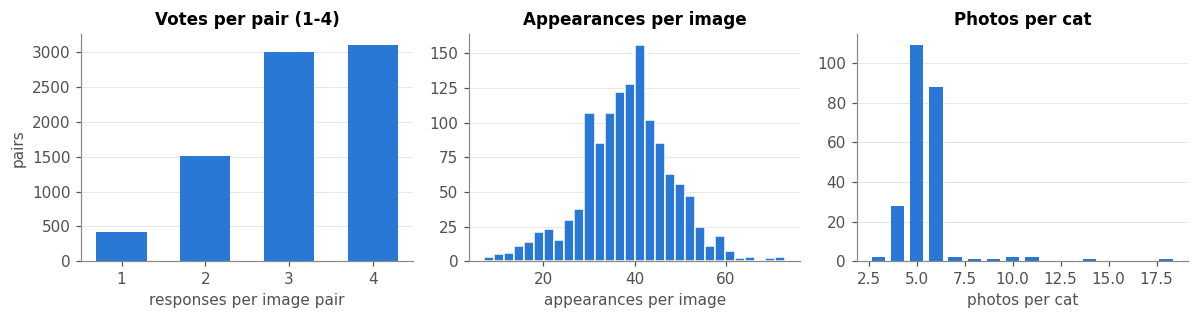

In [45]:
# @title
votes_u = train.groupby("pair_u").size()
orient = train.groupby("pair_u")["pair_o"].nunique()
votes_o = train.groupby("pair_o").size()
app_img = long.groupby("img").size()
app_cat = long.groupby("cat").size()
img_per_cat = long.groupby("cat")["img"].nunique()
prof_n = train.groupby("profile").size()

dep = pd.DataFrame({
    "units": [len(votes_u), len(app_img), len(app_cat), len(prof_n)],
    "rows per unit: min": [votes_u.min(), app_img.min(), app_cat.min(), prof_n.min()],
    "median": [votes_u.median(), app_img.median(), app_cat.median(), prof_n.median()],
    "max": [votes_u.max(), app_img.max(), app_cat.max(), prof_n.max()],
}, index=["image pair (unordered)", "image (appearances)", "cat (appearances)", "annotator profile (rows)"])
display(dep)
print(f"pairs shown in both orders: {(orient == 2).sum():,} of {len(orient):,} ({(orient == 2).mean():.0%})")
print(f"ordered pairs answered twice: {(votes_o == 2).sum():,}; answered once: {(votes_o == 1).sum():,}")
print(f"images per cat: min {img_per_cat.min()}, median {img_per_cat.median():.0f}, max {img_per_cat.max()}")

fig, axes = plt.subplots(1, 3, figsize=(11, 3))
vc = votes_u.value_counts().sort_index()
axes[0].bar(vc.index, vc.values, color=BLUE, width=0.6); axes[0].set_xlabel("responses per image pair")
axes[0].set_ylabel("pairs"); axes[0].set_title("Votes per pair (1-4)"); axes[0].set_xticks(vc.index)
axes[1].hist(app_img, bins=30, color=BLUE, edgecolor="white"); axes[1].set_xlabel("appearances per image")
axes[1].set_title("Appearances per image")
vc2 = img_per_cat.value_counts().sort_index()
axes[2].bar(vc2.index, vc2.values, color=BLUE, width=0.7); axes[2].set_xlabel("photos per cat")
axes[2].set_title("Photos per cat")
for ax in axes: ax.grid(axis="x", visible=False)
save(fig, "2_3_dependence")

In [46]:
# @title
def wilson(k, n, z=1.96):
    p = k / n; den = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / den
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return centre - half, centre + half

def cluster_boot_rate(df, cluster, B=2000, seed=SEED):
    g = df.groupby(cluster)["y"].agg(["sum", "count"])
    s, c = g["sum"].to_numpy(), g["count"].to_numpy()
    idx = np.random.default_rng(seed).integers(0, len(g), size=(B, len(g)))
    return np.quantile(s[idx].sum(1) / c[idx].sum(1), [0.025, 0.975])

rows = []
for label, d in [("all rows", train), ("between-cat", train[train.comparison_type == "between_cats"]),
                 ("within-cat", train[train.comparison_type == "within_cat"])]:
    k, n = d.y.sum(), len(d)
    lo, hi = wilson(k, n); blo, bhi = cluster_boot_rate(d, "pair_u")
    rows.append({"subset": label, "n": n, "P(choose A)": k / n, "95% CI (rows independent)": f"{lo:.3f}-{hi:.3f}",
                 "95% CI (bootstrap over pairs)": f"{blo:.3f}-{bhi:.3f}"})
side = pd.DataFrame(rows).set_index("subset"); display(side)
p_A = train.y.mean()
gamma = np.log(p_A / (1 - p_A))
print(f"left-side effect on the log-odds scale: gamma = {gamma:.3f}")

,n,P(choose A),95% CI (rows independent),95% CI (bootstrap over pairs)
subset,,,,
all rows,24896,0.5190,0.513-0.525,0.513-0.525
between-cat,21893,0.5197,0.513-0.526,0.513-0.526
within-cat,3003,0.5142,0.496-0.532,0.497-0.531


left-side effect on the log-odds scale: gamma = 0.076


**Rows are strongly clustered.** Every image appears about 39 times and every cat about 200 times, but each pair has only 1–4 votes. Consequently, the appeal of an image or a cat can be estimated quite precisely, whereas the probability for a single pair rests on at most four votes. For this reason, cross-validation folds are built by pair or by cat, and confidence intervals use a **bootstrap** that resamples whole pairs instead of single rows.

**Image A, on the left, is chosen 51.9% of the time**, and both intervals exclude 50%. Although the effect is small, it is systematic, so **every model includes a left-side effect**. The model that only uses this effect (predicting 0.519 for every row, log loss ≈ 0.692) is **the minimum baseline that every model must beat**.

## 2.3 Do people agree?

Next, we ask how often two people choose the same image from the same pair. We use the **pairwise agreement**, the probability that two randomly chosen votes on a pair pick the same image (50% under random choice), and compare it with the majority share, which is high by construction when a pair has few votes.

In [47]:
# @title
multi = train[train.pair_u.map(votes_u) >= 2]
g = multi.groupby("pair_u")
n_v = g.size()
k_top = g["winner_img"].agg(lambda s: s.value_counts().iloc[0])
type_u = g["comparison_type"].first()

def coinflip_majority(n):
    x = np.arange(n + 1); return float((stats.binom.pmf(x, n, 0.5) * np.maximum(x, n - x) / n).sum())

def agreement_table(mask):
    n, k = n_v[mask], k_top[mask]
    pairs_agree = (k * (k - 1) + (n - k) * (n - k - 1)).sum() / (n * (n - 1)).sum()
    return {"pairs (>=2 votes)": int(mask.sum()),
            "majority share: observed": (k / n).mean(),
            "majority share: expected under random choice": np.mean([coinflip_majority(v) for v in n]),
            "pairwise agreement (two votes, same image)": pairs_agree}

# kappa on ordered pairs answered exactly twice
tw = train[train.pair_o.map(votes_o) == 2].sort_values(["pair_o", "train_row_id"])
f, s = tw.groupby("pair_o").nth(0).set_index("pair_o"), tw.groupby("pair_o").nth(1).set_index("pair_o")
s = s.loc[f.index]
def kappa(m):
    y1, y2 = f.y[m].to_numpy(), s.y[m].to_numpy()
    po_, pe = np.mean(y1 == y2), y1.mean() * y2.mean() + (1 - y1.mean()) * (1 - y2.mean())
    return (po_ - pe) / (1 - pe)

agree = pd.DataFrame({
    "all": {**agreement_table(np.ones(len(n_v), bool))},
    "between-cat": {**agreement_table((type_u == "between_cats").to_numpy())},
    "within-cat": {**agreement_table((type_u == "within_cat").to_numpy())},
}).T
display(agree)

,pairs (>=2 votes),majority share: observed,majority share: expected under random choice,"pairwise agreement (two votes, same image)"
all,7627.0,0.7542,0.7245,0.5547
between-cat,6611.0,0.7544,0.7224,0.5574
within-cat,1016.0,0.7530,0.7383,0.5305


**People agree only slightly more than chance.** The majority share of 75% looks high, but random choice would already give 72%, whereas **pairwise agreement is only 55.5%** (53% for two photos of the same cat). This raises the question of why agreement is so low. If it is because the two images are often similarly appealing, agreement should rise when the two cats differ more. To test this, we measure each cat's appeal on one random half of the pairs and agreement on the other half.

,pairs,gap_mid,pairwise agreement,lo,hi
bin,,,,,
"(-0.001, 0.0315]",1324,0.0147,0.5365,0.5224,0.5528
"(0.0315, 0.0657]",1322,0.0483,0.5304,0.5158,0.5447
"(0.0657, 0.107]",1321,0.0850,0.5440,0.5297,0.5599
"(0.107, 0.169]",1322,0.1340,0.5684,0.5525,0.5832
"(0.169, 0.506]",1322,0.2212,0.6033,0.5860,0.6185


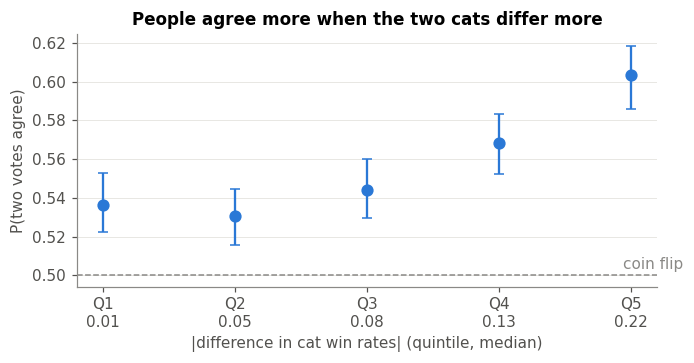

In [48]:
# @title
bt_rows = train[train.comparison_type == "between_cats"]
pairs_bt = bt_rows.pair_u.unique()
half = pd.Series(np.random.default_rng(SEED).integers(0, 2, len(pairs_bt)), index=pairs_bt)
out = []
for h in (0, 1):
    est = long[(long.type == "between_cats") & (long.pair_u.map(half) != h)].groupby("cat")["won"].mean()
    ev = multi[(multi.comparison_type == "between_cats") & (multi.pair_u.map(half) == h)]
    gg = ev.groupby("pair_u")
    d = pd.DataFrame({"n": gg.size(), "k": gg["winner_img"].agg(lambda s_: s_.value_counts().iloc[0]),
                      "a": gg["a_cat"].first(), "b": gg["b_cat"].first()})
    d["gap"] = (d.a.map(est) - d.b.map(est)).abs()
    out.append(d.dropna())
d = pd.concat(out)
d["bin"] = pd.qcut(d.gap, 5)
d["agree_num"] = d.k * (d.k - 1) + (d.n - d.k) * (d.n - d.k - 1); d["agree_den"] = d.n * (d.n - 1)
by = d.groupby("bin", observed=True).agg(pairs=("n", "size"), gap_mid=("gap", "median"),
                                         num=("agree_num", "sum"), den=("agree_den", "sum"))
by["pairwise agreement"] = by.num / by.den
# bootstrap CI by resampling pairs within bin
ci = []
for b_, dd in d.groupby("bin", observed=True):
    idx = np.random.default_rng(SEED).integers(0, len(dd), (1000, len(dd)))
    nu, de = dd.agree_num.to_numpy(), dd.agree_den.to_numpy()
    ci.append(np.quantile(nu[idx].sum(1) / de[idx].sum(1), [0.025, 0.975]))
by[["lo", "hi"]] = np.array(ci)
display(by[["pairs", "gap_mid", "pairwise agreement", "lo", "hi"]])

fig, ax = plt.subplots(figsize=(6.4, 3.4))
x = np.arange(len(by))
ax.errorbar(x, by["pairwise agreement"], yerr=[by["pairwise agreement"] - by.lo, by.hi - by["pairwise agreement"]],
            fmt="o", color=BLUE, ms=7, capsize=3, lw=1.5)
ax.axhline(0.5, color=GREY, lw=1, ls="--"); ax.text(len(by) - 0.6, 0.503, "coin flip", color=GREY, ha="right")
ax.set_xticks(x, [f"Q{i+1}\n{m:.2f}" for i, m in enumerate(by.gap_mid)])
ax.set_xlabel("|difference in cat win rates| (quintile, median)"); ax.set_ylabel("P(two votes agree)")
ax.set_title("People agree more when the two cats differ more")
ax.grid(axis="x", visible=False)
save(fig, "2_5_agreement_by_gap")

**Agreement rises as the two cats differ more**, from about 53% to 60%. Hence disagreement is not careless answering: each pair has its own true probability of A being chosen, and when two cats are similar this probability is close to 0.5. As a result, **a single choice is very noisy**, and §3.3 measures how much accuracy this leaves possible. At the same time, the pattern supports a model based on the difference in appeal, that is, the Bradley–Terry model.

## 2.4 How much do cats and photos differ?

The Bradley–Terry model gives every image and cat a score, but finite scores exist only if the comparison network is **connected** and the "who beat whom" network is **strongly connected**. We check both conditions first. Since raw win rates also contain noise, we then separate real differences from noise in two ways: we split the pairs randomly into two halves and check whether the win rates from the two halves agree, and we plot each win rate against the range expected from noise alone.

In [49]:
# @title
def network_summary(a, b, w, l):
    G = nx.Graph(); G.add_edges_from(zip(a, b))
    D = nx.DiGraph(); D.add_edges_from(zip(w, l))
    deg = pd.Series(dict(G.degree()))
    return {"nodes": G.number_of_nodes(), "edges (distinct pairs)": G.number_of_edges(),
            "connected components": nx.number_connected_components(G),
            "strongly connected components (wins)": nx.number_strongly_connected_components(D),
            "opponents per node: min": deg.min(), "median": deg.median(), "max": deg.max()}

wt = train[train.comparison_type == "within_cat"]
net = pd.DataFrame({
    "images (all rows)": network_summary(train.a_image, train.b_image, train.winner_img, train.loser_img),
    "cats (between-cat rows)": network_summary(bt_rows.a_cat, bt_rows.b_cat, bt_rows.winner_cat, bt_rows.loser_cat),
}).T
display(net)

# within each cat: are its photos connected by within-cat comparisons?
comp = []
for c, dd in wt.groupby("a_cat"):
    G = nx.Graph(); G.add_nodes_from(long.loc[long.cat == c, "img"].unique()); G.add_edges_from(zip(dd.a_image, dd.b_image))
    comp.append(nx.number_connected_components(G))
comp = pd.Series(comp)
print(f"cats with within-cat comparisons: {len(comp)} of {len(app_cat)}; "
      f"photos of a cat form one connected group in {(comp == 1).mean():.0%} of them")

,nodes,edges (distinct pairs),connected components,strongly connected components (wins),opponents per node: min,median,max
images (all rows),1296.0,8049.0,1.0,1.0,2.0,13.0,23.0
cats (between-cat rows),237.0,6917.0,1.0,1.0,49.0,59.0,66.0


cats with within-cat comparisons: 237 of 237; photos of a cat form one connected group in 76% of them


In [50]:
# @title
def winrates(sub, unit):
    return sub.groupby(unit)["won"].agg(["mean", "size"])

def split_half(sub, unit, reps=20, seed=SEED):
    pairs = sub.pair_u.unique(); r_ = []
    gen = np.random.default_rng(seed)
    for _ in range(reps):
        h = pd.Series(gen.integers(0, 2, len(pairs)), index=pairs)
        m = sub.pair_u.map(h)
        w0, w1 = winrates(sub[m == 0], unit), winrates(sub[m == 1], unit)
        j = w0.join(w1, lsuffix="0", rsuffix="1", how="inner")
        r_.append(np.corrcoef(j.mean0, j.mean1)[0, 1])
    r = float(np.mean(r_)); return r, float(np.std(r_)), 2 * r / (1 + r)

specs = [("cat (between-cat rows)", long[long.type == "between_cats"], "cat"),
         ("image (all rows)", long, "img"),
         ("image (between-cat rows)", long[long.type == "between_cats"], "img"),
         ("image (within-cat rows only)", long[long.type == "within_cat"], "img")]
rel = []
for label, sub, unit in specs:
    w = winrates(sub, unit)
    noise = (0.25 / w["size"]).mean()            # binomial variance at p = 0.5
    true_var = max(w["mean"].var() - noise, 0)
    r, sd, sb = split_half(sub, unit)
    rel.append({"unit": label, "units": len(w), "median n": w["size"].median(),
                "win rate: min": w["mean"].min(), "max": w["mean"].max(),
                "outside noise range": float(((w["mean"] - 0.5).abs() > 2 * np.sqrt(0.25 / w["size"])).mean()),
                "observed var": w["mean"].var(), "noise var": noise, "signal share": true_var / w["mean"].var(),
                "correlation between two halves": r})
rel = pd.DataFrame(rel).set_index("unit"); display(rel)

v_cat = rel.loc["cat (between-cat rows)", "observed var"] - rel.loc["cat (between-cat rows)", "noise var"]
v_img = rel.loc["image (between-cat rows)", "observed var"] - rel.loc["image (between-cat rows)", "noise var"]
print(f"true variance of image appeal (between-cat rows): {v_img:.4f} = between-cat {v_cat:.4f} ({v_cat / v_img:.0%}) "
      f"+ within-cat {v_img - v_cat:.4f} ({1 - v_cat / v_img:.0%})")

,units,median n,win rate: min,max,outside noise range,observed var,noise var,signal share,correlation between two halves
unit,,,,,,,,,
cat (between-cat rows),237,186.0,0.2395,0.7463,0.4177,0.0091,0.0014,0.8499,0.6904
image (all rows),1296,39.0,0.0952,0.8485,0.2199,0.0176,0.0071,0.5950,0.3503
image (between-cat rows),1296,34.0,0.0714,0.9000,0.2284,0.0204,0.0081,0.5999,0.3479
image (within-cat rows only),1251,5.0,0.0000,1.0000,0.0488,0.0754,0.0653,0.1335,0.1223


true variance of image appeal (between-cat rows): 0.0122 = between-cat 0.0077 (63%) + within-cat 0.0045 (37%)


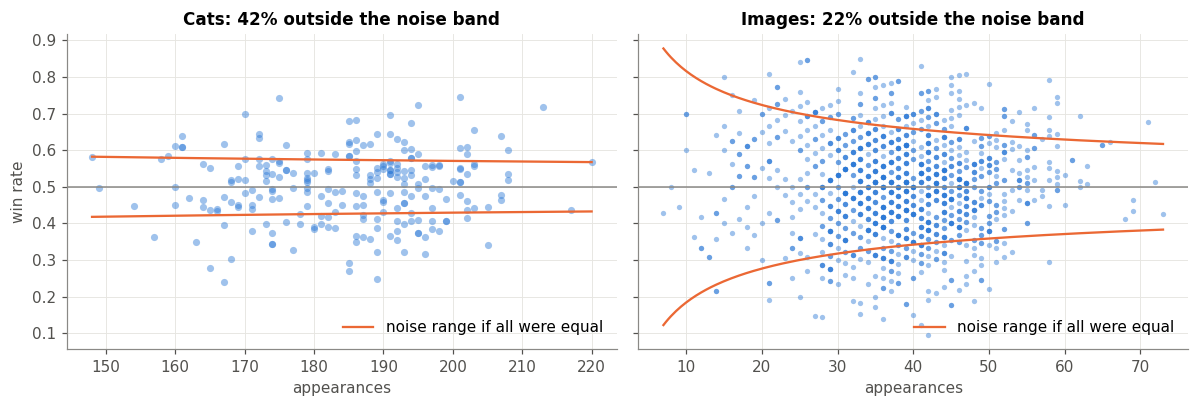

In [51]:
# @title
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, (label, sub, unit), colr in zip(axes, [specs[0], specs[1]], [BLUE, BLUE]):
    w = winrates(sub, unit)
    ax.scatter(w["size"], w["mean"], s=12 if unit == "img" else 22, alpha=0.45, color=colr, linewidths=0)
    grid = np.linspace(w["size"].min(), w["size"].max(), 200)
    band = 2 * np.sqrt(0.25 / grid)
    ax.plot(grid, 0.5 + band, color=ORANGE, lw=1.5, label="noise range if all were equal")
    ax.plot(grid, 0.5 - band, color=ORANGE, lw=1.5)
    ax.axhline(0.5, color=GREY, lw=1)
    share = rel.loc[label, "outside noise range"]
    ax.set_title(f"{label.split(' ')[0].capitalize()}s: {share:.0%} outside the noise band")
    ax.set_xlabel("appearances"); ax.legend(loc="lower right")
axes[0].set_ylabel("win rate")
save(fig, "2_7_funnel")

**Both network conditions hold, so the model is well defined.** Furthermore, **cats differ for real, while photos of the same cat differ much less reliably**: 42% of cats lie outside the noise range, compared with about a fifth of images, and cat win rates from the two halves agree closely (correlation 0.69, against 0.35 for images). **About two thirds of the real variation in image appeal comes from which cat is shown, and one third from which photo.** Therefore each image score should have two levels, a cat score plus a smaller photo deviation, and because many photos have few comparisons, both need a **ridge penalty**.

## 2.5 Image labels and the person choosing

For new cats no score can be estimated, so we ask whether the image labels themselves carry information, namely which photo of the cat it is and how many photos the cat has. In addition, we check whether the person's characteristics are related to the side chosen.

In [52]:
# @title
long["first_photo"] = long.idx.eq(1)
rows = []
for label, sub in [("all rows", long), ("between-cat", long[long.type == "between_cats"]),
                   ("within-cat", long[long.type == "within_cat"])]:
    for fp, dd in sub.groupby("first_photo"):
        k, n = dd.won.sum(), len(dd); lo, hi = wilson(k, n)
        rows.append({"subset": label, "photo": "photo 0001" if fp else "photo 0002+", "appearances": n,
                     "win rate": k / n, "95% CI": f"{lo:.3f}-{hi:.3f}"})
display(pd.DataFrame(rows).set_index(["subset", "photo"]))

# within-cat rows where exactly one side is photo 0001: a clean comparison with the cat held fixed
w1 = train[(train.comparison_type == "within_cat") & ((train.a_idx == 1) ^ (train.b_idx == 1))]
k = int(((w1.a_idx == 1) & (w1.y == 1)).sum() + ((w1.b_idx == 1) & (w1.y == 0)).sum())
lo, hi = wilson(k, len(w1))
print(f"within-cat duels 'photo 0001 vs another photo of the same cat': photo 0001 wins {k / len(w1):.3f} "
      f"(95% CI {lo:.3f}-{hi:.3f}, n = {len(w1)}))")

cat_wr = long[long.type == "between_cats"].groupby("cat")["won"].mean()
r_ = np.corrcoef(img_per_cat.loc[cat_wr.index], cat_wr)[0, 1]
print(f"photos per cat vs cat win rate: correlation = {r_:.3f}")

appearances  win rate       95% CI
subset      photo                                          
all rows    photo 0002+        40868    0.4948  0.490-0.500
            photo 0001          8924    0.5236  0.513-0.534
between-cat photo 0002+        35926    0.4957  0.490-0.501
            photo 0001          7860    0.5198  0.509-0.531
within-cat  photo 0002+         4942    0.4889  0.475-0.503
            photo 0001          1064    0.5517  0.522-0.581

within-cat duels 'photo 0001 vs another photo of the same cat': photo 0001 wins 0.552 (95% CI 0.522-0.581, n = 1064))
photos per cat vs cat win rate: correlation = 0.037


In [53]:
# @title
complete = train[~train.demo_missing]
rows = []
for c in DEMO:
    rates = complete.groupby(c).y.mean()
    rows.append({"field": c, "levels": complete[c].nunique(),
                 "lowest P(A) across levels": rates.min(), "highest P(A) across levels": rates.max(),
                 "largest difference": rates.max() - rates.min(),
                 "most common level": complete[c].value_counts(normalize=True).index[0],
                 "its share": complete[c].value_counts(normalize=True).iloc[0]})
display(pd.DataFrame(rows).set_index("field").round(3))

miss = pd.DataFrame({
    "rows": train.groupby("demo_missing").size(),
    "P(choose A)": train.groupby("demo_missing").y.mean(),
}).rename(index={False: "annotator info present", True: "annotator info missing"})
lo, hi = wilson(train.loc[train.demo_missing, "y"].sum(), train.demo_missing.sum())
display(miss); print(f"missing-info rows: 95% CI for P(A) {lo:.3f}-{hi:.3f}")

,levels,lowest P(A) across levels,highest P(A) across levels,largest difference,most common level,its share
field,,,,,,
gender,2,0.514,0.522,0.008,man,0.574
pet_history,3,0.494,0.532,0.038,never,0.382
pet_care,4,0.499,0.533,0.034,past_regular,0.293
pet_contact,5,0.505,0.528,0.023,rarely,0.310
future_pet,3,0.488,0.527,0.039,yes,0.704
mbti_ie,3,0.497,0.550,0.053,I,0.574


,rows,P(choose A)
demo_missing,,
annotator info present,24388,0.5172
annotator info missing,508,0.6043


missing-info rows: 95% CI for P(A) 0.561-0.646


**Photo 1 tends to be a cat's better photo, but the effect is small** (it wins 55% of duels against other photos of the same cat), and the number of photos is unrelated to appeal. Thus, **for new cats the labels give almost no information**, and they will be predicted close to the baseline unless the content of the photos is used (Section 5).

**The person's characteristics change the side chosen only a little** (the share of A differs by at most about 5 percentage points between groups), but **rows without information about the person choose A 60% of the time**. These characteristics therefore enter the model as left-side effects, with `missing` as its own group. Whether different groups also prefer different cats is a separate question, tested in §3.4.

## 2.6 From exploration to a model

Taken together, the exploration points to one model. Cats, and to a lesser extent photos, differ in appeal; the left side has a small constant advantage; and single choices are noisy, especially when two images are similar. These are the assumptions of the **Bradley–Terry model**, written as a logistic regression:

$$
P(\text{A chosen}) = \sigma\big(\gamma + s(A) - s(B)\big), \qquad s(\text{image}) = c(\text{cat}) + v(\text{image}),
$$

where $\sigma$ is the logistic function.

The exploration also suggests three possible limits on how well this model can predict: **disagreement between people** (§2.3), **differences between groups of people** (§2.5) and **missing information about new cats** (§2.5). Section 3 examines them in turn.

---
# 3. Statistical Analysis

This section first sets up the model and a fair way to evaluate it (§3.1). It then measures how predictable the choices are (§3.2). Since the answer shows that the model stops well short of perfect, we next test the two possible reasons that the table allows us to check: disagreement between people (§3.3) and differences in how people rank the cats (§3.4).

## 3.1 Model and validation design

To give a probability for every test row, we turn the findings of Section 2 into one logistic regression:

$$
P(y_i = 1) = \sigma\Big(\underbrace{\gamma + \textstyle\sum_j \delta_j z_{ij} + \pi_{\text{profile}(i)}}_{\text{left-side effect}} + \underbrace{c(\text{cat}_A) - c(\text{cat}_B)}_{\text{cat scores}} + \underbrace{v(A) - v(B)}_{\text{photo deviations}} + \underbrace{\theta^\top\{f(A) - f(B)\}}_{\text{label features}}\Big),
$$

where $y_i = 1$ if image A was chosen. The cat score and photo deviation come from §2.4, the label features $f$ (photo 1, number of photos) from §2.5, and the left-side effect, which may differ by the person's characteristics $z$ and profile, from §2.2 and §2.5. Because many photos have few comparisons, all scores are estimated with **ridge** penalties, and a cat or photo never seen in training gets score 0.

We judge the model by **log loss**, because the test file asks for a probability and log loss rewards honest probabilities. A value only has meaning next to reference points, so we compare it with a random guess (always 0.5) for every row (log loss = log 2 ≈ 0.693), the position-only model (§2.2) and the **ceiling**, the best value any model can reach given that people disagree (§3.3). To put all results on one scale, we also define the **share of the gap closed**, $\frac{\text{position only} - \text{model}}{\text{position only} - \text{ceiling}}$, which is 0% for no improvement and 100% for the best possible model.

Since the test outcomes are hidden, test performance has to be estimated by cross-validation, and here the way the data are split matters. The same pairs, images and cats appear in many rows, so the data form a comparison graph. A random split would put the same pair, image or cat in both the training and the validation part, so the model would be tested on comparisons it has already seen. This is **data leakage**, and it makes the results look too good. What must be kept out of training depends on what the model has to predict:

| Prediction goal | Kept out of training | In our test set? | Our split |
|---|---|---|---|
| new matchups of known images | all votes on the held-out pairs, including the reversed A/B order | yes | pair-CV |
| new images of known cats | every row with a held-out image | no (all new images belong to new cats) | covered by cat-CV |
| new cats | every row with a held-out cat | yes (half of the test rows) | cat-CV |
| new votes on a pair already answered | nothing (random split) | no | not used |

We therefore use **pair-CV** (5 folds of pairs) for rows with seen cats and **cat-CV** (5 folds of cats) for rows with new cats, and weight the results by the shares of the five matching cells in the test set:

In [54]:
# @title
DEMO = ["gender", "pet_history", "pet_care", "pet_contact", "future_pet", "mbti_ie"]
train = pd.read_csv(DATA_DIR / "train.csv", encoding="utf-8-sig", keep_default_na=False, na_values=[""])
test = pd.read_csv(DATA_DIR / "test.csv", encoding="utf-8-sig", keep_default_na=False, na_values=[""])

# photos per cat, counted from the image paths in BOTH files (IDs only, no outcomes)
all_imgs = pd.Series(pd.concat([train.a_image, train.b_image, test.a_image, test.b_image]).unique())
n_photos = all_imgs.str.split("/").str[0].value_counts()

def construct(df):
    df = df.copy()
    df[DEMO] = df[DEMO].fillna("missing")
    df["pair_u"] = ["||".join(sorted(p)) for p in zip(df.a_image, df.b_image)]
    df["a_idx"] = df.a_image.str.extract(r"_(\d+)\.jpg$")[0].astype(int)
    df["b_idx"] = df.b_image.str.extract(r"_(\d+)\.jpg$")[0].astype(int)
    df["a_n"], df["b_n"] = df.a_cat.map(n_photos), df.b_cat.map(n_photos)
    df["within"] = (df.comparison_type == "within_cat").astype(int)
    df["profile"] = df[DEMO].agg("|".join, axis=1)
    return df.reset_index(drop=True)

train, test = construct(train), construct(test)
train["y"] = (train.choice == "A").astype(int)
y = train.y.to_numpy()

# test strata (§1.3) and the five "cells" we will reproduce in validation
train_cats = set(train.a_cat) | set(train.b_cat)
test["n_seen"] = test.a_cat.isin(train_cats).astype(int) + test.b_cat.isin(train_cats).astype(int)
def cell_of(n_seen, within):
    return np.select([(n_seen == 2) & (within == 0), (n_seen == 2) & (within == 1), n_seen == 1,
                      (n_seen == 0) & (within == 0), (n_seen == 0) & (within == 1)],
                     ["seen | between", "seen | within", "one new cat", "two new | between", "two new | within"], default="?")
test["cell"] = cell_of(test.n_seen, test.within)
CELLS = ["seen | between", "seen | within", "one new cat", "two new | between", "two new | within"]
W = test.cell.value_counts().reindex(CELLS) / len(test)
display(pd.DataFrame({"test rows": test.cell.value_counts().reindex(CELLS), "weight": W}))

,test rows,weight
cell,,
seen | between,2743,0.4407
seen | within,369,0.0593
one new cat,1556,0.2500
two new | between,926,0.1488
two new | within,630,0.1012


In [55]:
# @title
def id_features(df):
    # f(A) - f(B): first-photo indicator, log number of photos of the cat
    return np.column_stack([(df.a_idx == 1).astype(float) - (df.b_idx == 1), np.log(df.a_n) - np.log(df.b_n)])

class BTModel:
    # Bradley-Terry logistic regression with ridge penalty.
    # sc, si = column scales for cat / image scores (0 = term not used); penalty on that block = 1 / scale^2.
    # feats = add ID features; groups = add group-specific position effects (one dummy per field level);
    # prof = scale of profile-specific position effects (one dummy per annotator profile, 0 = not used);
    # extra = callable(df) -> extra columns.
    def __init__(self, sc=0.0, si=0.0, feats=False, groups=False, prof=0.0, extra=None, C=1.0):
        self.sc, self.si, self.feats, self.groups, self.prof, self.extra, self.C = sc, si, feats, groups, prof, extra, C

    def _diff_block(self, a, b, index, scale):
        n = len(a); r = np.arange(n)
        ia, ib = a.map(index), b.map(index)
        ma, mb = ia.notna().to_numpy(), ib.notna().to_numpy()
        rows = np.r_[r[ma], r[mb]]
        cols = np.r_[ia[ma].astype(int), ib[mb].astype(int)]
        vals = np.r_[np.ones(ma.sum()), -np.ones(mb.sum())] * scale
        return sp.csr_matrix((vals, (rows, cols)), shape=(n, len(index)))   # duplicates (same cat) sum to 0

    def design(self, df):
        blocks = []
        if self.sc > 0: blocks.append(self._diff_block(df.a_cat, df.b_cat, self.cat_index, self.sc))
        if self.si > 0: blocks.append(self._diff_block(df.a_image, df.b_image, self.img_index, self.si))
        if self.feats: blocks.append(sp.csr_matrix(id_features(df)))
        if self.groups: blocks.append(sp.csr_matrix(np.column_stack([(df[c] == l).to_numpy(float) for c, l in self.levels])))
        if self.prof > 0:
            ip = df.profile.map(self.prof_index); m_ = ip.notna().to_numpy()
            blocks.append(sp.csr_matrix((np.full(m_.sum(), self.prof), (np.where(m_)[0], ip[m_].astype(int))),
                                        shape=(len(df), len(self.prof_index))))   # unseen profile -> no term
        if self.extra is not None: blocks.append(sp.csr_matrix(self.extra(df)))
        if not blocks: blocks.append(sp.csr_matrix((len(df), 1)))
        return sp.hstack(blocks).tocsr()

    def fit(self, df, w=None):
        cats = pd.unique(np.r_[df.a_cat, df.b_cat]); imgs = pd.unique(np.r_[df.a_image, df.b_image])
        self.cat_index = pd.Series(np.arange(len(cats)), index=cats)
        self.img_index = pd.Series(np.arange(len(imgs)), index=imgs)
        self.levels = [(c, l) for c in DEMO for l in sorted(df[c].unique())]
        profs = df.profile.unique(); self.prof_index = pd.Series(np.arange(len(profs)), index=profs)
        self.model = LogisticRegression(C=self.C, max_iter=3000, tol=1e-6).fit(self.design(df), df.y, sample_weight=w)
        return self

    def predict(self, df): return self.model.predict_proba(self.design(df))[:, 1]
    def logit(self, df): return self.model.decision_function(self.design(df))

    def scores(self):
        k = 0; out = {}
        coef = self.model.coef_.ravel()
        if self.sc > 0: out["cat"] = pd.Series(coef[:len(self.cat_index)] * self.sc, index=self.cat_index.index); k = len(self.cat_index)
        if self.si > 0: out["img"] = pd.Series(coef[k:k + len(self.img_index)] * self.si, index=self.img_index.index)
        return out

def logloss_rows(y_, p):
    p = np.clip(p, 1e-9, 1 - 1e-9); return -(y_ * np.log(p) + (1 - y_) * np.log(1 - p))

In [56]:
# @title
# ---- folds ---------------------------------------------------------------
def pair_folds(df, k=5, seed=SEED):
    pairs = df.pair_u.unique(); fold_of = pd.Series(np.random.default_rng(seed).permutation(len(pairs)) % k, index=pairs)
    f = df.pair_u.map(fold_of).to_numpy()
    return [(np.where(f != j)[0], np.where(f == j)[0]) for j in range(k)]

def cat_folds(df, k=5, seed=SEED):
    cats_ = np.array(sorted(set(df.a_cat) | set(df.b_cat)))
    fold_of = pd.Series(np.random.default_rng(seed).permutation(len(cats_)) % k, index=cats_)
    fa, fb = df.a_cat.map(fold_of).to_numpy(), df.b_cat.map(fold_of).to_numpy()
    out = []
    for j in range(k):
        held = (fa == j).astype(int) + (fb == j).astype(int)
        out.append((np.where(held == 0)[0], np.where(held > 0)[0], held))
    return out

def profile_folds(df, k=5, seed=SEED):
    profs = df.profile.unique(); fold_of = pd.Series(np.random.default_rng(seed).permutation(len(profs)) % k, index=profs)
    f = df.profile.map(fold_of).to_numpy()
    return [(np.where(f != j)[0], np.where(f == j)[0]) for j in range(k)]

PAIR_F, CAT_F, PROF_F = pair_folds(train), cat_folds(train), profile_folds(train)

# validation cell of every row under the scheme that reproduces it
cell_pair = np.where(train.within == 1, "seen | within", "seen | between")
cell_cat = np.empty(len(train), dtype=object)
for tr_idx, va_idx, held in CAT_F:
    h = held[va_idx]; w = train.within.to_numpy()[va_idx]
    cell_cat[va_idx] = np.where(h == 1, "one new cat", np.where(w == 1, "two new | within", "two new | between"))
fold_sizes = pd.DataFrame({
    "pair-CV validation rows": pd.Series(cell_pair).value_counts(),
    "cat-CV validation rows": pd.Series(cell_cat).value_counts()}).reindex(CELLS)
display(fold_sizes)
print("cat-CV: average share of rows available for training per fold:",
      f"{np.mean([len(t) / len(train) for t, _, _ in CAT_F]):.0%}")

,pair-CV validation rows,cat-CV validation rows
seen | between,21893.0,NaN
seen | within,3003.0,NaN
one new cat,NaN,17706.0
two new | between,NaN,4187.0
two new | within,NaN,3003.0


cat-CV: average share of rows available for training per fold: 66%


The three penalty strengths are chosen once by 3-fold pair-CV on the training data only; repeating this inside every outer fold gave exactly the same values.

In [57]:
# @title
SC_GRID = [0.3, 0.5, 0.7, 1.0, 1.5]          # cat-score scale   (penalty lambda_c = 1 / scale^2)
SI_GRID = [0.15, 0.3, 0.5, 0.7]              # photo-score scale (penalty lambda_v = 1 / scale^2)
PROF_GRID = [0.1, 0.3, 1.0]                  # profile scale     (penalty lambda_profile = 1 / scale^2)
t1 = time.time()
INNER = pair_folds(train, 3, SEED + 1)
def inner_loss(make):
    return sum(logloss_rows(train.y.to_numpy()[va], make().fit(train.iloc[tr]).predict(train.iloc[va])).sum()
               for tr, va in INNER) / len(train)

grid_both = {(sc, si): inner_loss(lambda sc=sc, si=si: BTModel(sc, si)) for sc in SC_GRID for si in SI_GRID}
grid_cat = {sc: inner_loss(lambda sc=sc: BTModel(sc)) for sc in SC_GRID}
grid_img = {si: inner_loss(lambda si=si: BTModel(0, si)) for si in SI_GRID}
BOTH = min(grid_both, key=grid_both.get)
grid_prof = {s_: inner_loss(lambda s_=s_: BTModel(*BOTH, feats=True, groups=True, prof=s_)) for s_ in PROF_GRID}
PROF = min(grid_prof, key=grid_prof.get)
T_ = {"cat": (min(grid_cat, key=grid_cat.get), 0), "img": (0, min(grid_img, key=grid_img.get)), "both": BOTH, "prof": PROF}
TUNED = {s_: [T_] * 5 for s_ in ["pair", "cat", "profile"]}
full_t = BOTH

path = pd.Series(grid_both).unstack()
path.index = [f"lambda_cat = {1 / s**2:.2f}" for s in path.index]
path.columns = [f"lambda_photo = {1 / s**2:.1f}" for s in path.columns]
display(Markdown("**Inner-CV log loss of the cat + photo model over the penalty grid** (lower is better)"))
display(path.style.format("{:.4f}").background_gradient(cmap="Blues_r", axis=None))
print(f"chosen: lambda_cat = {1 / BOTH[0]**2:.2f}, lambda_photo = {1 / BOTH[1]**2:.1f}, lambda_profile = {1 / PROF**2:.1f};"
      f"  cat-only model: lambda_cat = {1 / T_['cat'][0]**2:.2f};  photo-only model: lambda_photo = {1 / T_['img'][1]**2:.1f}")

full_bt = BTModel(*BOTH).fit(train)
cat_s, img_s = full_bt.scores()["cat"], full_bt.scores()["img"]
img_tot = img_s + img_s.index.str.split("/").str[0].map(cat_s).to_numpy()
share_cat = img_tot.index.str.split("/").str[0].map(cat_s).to_series().var() / img_tot.var()
print(f"SD of fitted cat scores {cat_s.std():.3f}, SD of photo deviations {img_s.std():.3f}; "
      f"share of the variance of fitted image scores due to the cat: {share_cat:.0%}")
print(f"tuning done in {time.time() - t1:.0f}s")

**Inner-CV log loss of the cat + photo model over the penalty grid** (lower is better)

,lambda_photo = 44.4,lambda_photo = 11.1,lambda_photo = 4.0,lambda_photo = 2.0
lambda_cat = 11.11,0.6592,0.6572,0.6604,0.6660
lambda_cat = 4.00,0.6567,0.6549,0.6588,0.6651
lambda_cat = 2.04,0.6566,0.6547,0.6587,0.6652
lambda_cat = 1.00,0.6568,0.6549,0.6590,0.6655
lambda_cat = 0.44,0.6570,0.6552,0.6592,0.6658


chosen: lambda_cat = 2.04, lambda_photo = 11.1, lambda_profile = 11.1;  cat-only model: lambda_cat = 2.04;  photo-only model: lambda_photo = 4.0
SD of fitted cat scores 0.512, SD of photo deviations 0.175; share of the variance of fitted image scores due to the cat: 85%
tuning done in 28s


**The photo scores need strong shrinkage, whereas the cat scores need only light shrinkage**, which agrees with §2.4. To confirm that the split really matters, we then fit the same model under five different splits.

In [58]:
# @title
# ---- out-of-fold predictions for any model spec ---------------------------
def oof(make_model, scheme):
    # make_model(tuned_dict) -> BTModel (or any object with fit/predict). Returns OOF probabilities.
    folds = {"pair": PAIR_F, "cat": CAT_F, "profile": PROF_F}[scheme]
    p = np.full(len(train), np.nan)
    for j, f in enumerate(folds):
        d_tr, va = train.iloc[f[0]], f[1]
        p[va] = make_model(TUNED[scheme][j]).fit(d_tr).predict(train.iloc[va])
    return p

def test_estimate(p_pair, p_cat):
    # combine pair-CV (seen cells) and cat-CV (new-cat cells) into per-cell and test-weighted log loss
    ll_pair, ll_cat = logloss_rows(y, p_pair), logloss_rows(y, p_cat)
    res = {}
    for c in CELLS:
        res[c] = ll_pair[cell_pair == c].mean() if c.startswith("seen") else ll_cat[cell_cat == c].mean()
    res["TEST ESTIMATE"] = sum(W[c] * res[c] for c in CELLS)
    return res

def other_metrics(y_, p):
    return {"accuracy": np.mean((p >= 0.5) == y_), "AUC": roc_auc_score(y_, p), "Brier": np.mean((p - y_) ** 2)}

def boot_diff(loss_a, loss_b, clusters, B=1000, seed=SEED):
    # cluster bootstrap CI of mean(loss_a - loss_b), resampling clusters (image pairs)
    d = pd.DataFrame({"d": loss_a - loss_b, "g": clusters}).groupby("g")["d"].agg(["sum", "count"])
    s, n = d["sum"].to_numpy(), d["count"].to_numpy()
    idx = np.random.default_rng(seed).integers(0, len(d), (B, len(d)))
    est = s.sum() / n.sum(); bs = s[idx].sum(1) / n[idx].sum(1)
    return est, *np.quantile(bs, [0.025, 0.975])

,out-of-fold log loss,accuracy,validation rows whose pair is in training,... both images in training,... both cats in training
split,,,,,
④ random rows,0.6470,62.0%,94%,100%,100%
ordered pairs (reverse order leaks),0.6473,61.9%,75%,100%,100%
① unordered pairs (pair-CV),0.6481,61.9%,0%,100%,100%
② held-out images,0.6560,60.5%,0%,0%,99%
③ held-out cats (cat-CV),0.6755,57.9%,0%,0%,0%


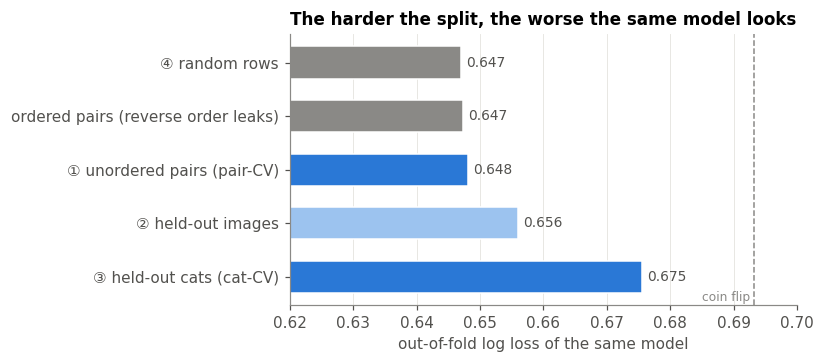

In [22]:
# @title
LEAK_BOTH, LEAK_PROF = TUNED["pair"][0]["both"], TUNED["pair"][0]["prof"]
gen = np.random.default_rng(SEED)

def split_by(keys_a, keys_b=None, k=5):
    # folds over a unit; a row goes to validation if it contains a held-out unit, to training only if it contains none
    units = np.array(sorted(set(keys_a) | (set(keys_b) if keys_b is not None else set())))
    fold_of = pd.Series(gen.permutation(len(units)) % k, index=units)
    fa = keys_a.map(fold_of).to_numpy(); fb = keys_b.map(fold_of).to_numpy() if keys_b is not None else fa
    return [(np.where((fa != j) & (fb != j))[0], np.where((fa == j) | (fb == j))[0]) for j in range(k)]

rand_f = gen.permutation(len(train)) % 5
SPLIT_SCHEMES = {
    "④ random rows": [(np.where(rand_f != j)[0], np.where(rand_f == j)[0]) for j in range(5)],
    "ordered pairs (reverse order leaks)": split_by(train.a_image + "|" + train.b_image),
    "① unordered pairs (pair-CV)": split_by(train.pair_u),
    "② held-out images": split_by(train.a_image, train.b_image),
    "③ held-out cats (cat-CV)": split_by(train.a_cat, train.b_cat),
}
rows = []
for name, folds in SPLIT_SCHEMES.items():
    p = np.full(len(train), np.nan); seen_pair = seen_img = seen_cat = 0
    for tr_i, va_i in folds:
        d_tr, d_va = train.iloc[tr_i], train.iloc[va_i]
        p[va_i] = BTModel(*LEAK_BOTH, feats=True, groups=True, prof=LEAK_PROF).fit(d_tr).predict(d_va)
        imgs_tr, cats_tr = set(d_tr.a_image) | set(d_tr.b_image), set(d_tr.a_cat) | set(d_tr.b_cat)
        seen_pair += d_va.pair_u.isin(set(d_tr.pair_u)).sum()
        seen_img += (d_va.a_image.isin(imgs_tr) & d_va.b_image.isin(imgs_tr)).sum()
        seen_cat += (d_va.a_cat.isin(cats_tr) & d_va.b_cat.isin(cats_tr)).sum()
    n = sum(len(f[1]) for f in folds)
    rows.append({"split": name, "out-of-fold log loss": logloss_rows(y, p).mean(), "accuracy": np.mean((p >= 0.5) == y),
                 "validation rows whose pair is in training": seen_pair / n,
                 "... both images in training": seen_img / n, "... both cats in training": seen_cat / n})
leak = pd.DataFrame(rows).set_index("split")
display(leak.style.format({"out-of-fold log loss": "{:.4f}", "accuracy": "{:.1%}"} |
                          {c: "{:.0%}" for c in leak.columns[2:]}))
leak.to_csv(OUT_DIR / "leakage_by_split.csv")

fig, ax = plt.subplots(figsize=(7.6, 3.4))
yy = np.arange(len(leak))[::-1]
cols = [GREY, GREY, BLUE, "#9cc3ef", BLUE]
ax.barh(yy, leak["out-of-fold log loss"] - 0.62, left=0.62, color=cols, height=0.6, edgecolor="white")
for y_, v in zip(yy, leak["out-of-fold log loss"]):
    ax.text(v + 0.0008, y_, f"{v:.3f}", va="center", fontsize=9, color=INK)
ax.set_yticks(yy, leak.index); ax.set_xlim(0.62, 0.70); ax.set_xlabel("out-of-fold log loss of the same model")
ax.axvline(np.log(2), color=GREY, ls="--", lw=1); ax.text(np.log(2) - 0.0005, yy[-1] - 0.45, "coin flip", ha="right", fontsize=8, color=GREY)
ax.set_title("The harder the split, the worse the same model looks"); ax.grid(axis="y", visible=False)
save(fig, "3_1_leakage_by_split")

**A random split makes the model look better than it is.** Under a random split, 94% of validation rows show a pair that is also in training, and the log loss is 0.647. With new images it rises to 0.656 and with new cats to 0.675. **A random split would therefore suggest a test log loss of about 0.647 (accuracy 62%), while the test-matched estimate below is 0.665 (accuracy 59%).** All further results use the test-matched design.

## 3.2 How predictable are the choices?

To see what each kind of information adds, we build the model up one part at a time and record the cross-validated log loss in each test cell, together with the test-weighted estimate. The ceiling in the last row is derived in §3.3.

In [23]:
# @title
# ceiling from §3.3 (beta-binomial, derived and checked in §3.3) -- needed for the gap-closed column
def pair_votes(df):
    # votes for the alphabetically first image of each unordered pair
    first = df.pair_u.str.split(r"\|\|").str[0]
    won_first = np.where(df.a_image == first, df.y, 1 - df.y)
    return pd.DataFrame({"pair_u": df.pair_u, "k": won_first, "type": df.comparison_type}).groupby("pair_u").agg(
        k=("k", "sum"), n=("k", "size"), type=("type", "first"))

def betabinom_negll(log_a, k, n):
    a = np.exp(log_a)
    return -(special.betaln(k + a, n - k + a) - special.betaln(a, a)).sum()   # binomial coefficient omitted (constant)

def fit_a(votes):
    v = votes[votes.n >= 2]
    r = optimize.minimize_scalar(lambda la: betabinom_negll(la, v.k.to_numpy(), v.n.to_numpy()), bounds=(-3, 6), method="bounded")
    return float(np.exp(r.x))

GAMMA = float(np.log(y.mean() / (1 - y.mean())))
def ceiling(a, gamma=GAMMA, m=4001):
    # expected loss of an oracle that knows each pair's true p, with p ~ Beta(a, a) and the position shift gamma
    p = np.linspace(1e-6, 1 - 1e-6, m); w = stats.beta.pdf(p, a, a); w /= w.sum()
    pA = special.expit(special.logit(p) + gamma)                         # P(A chosen) for this orientation
    H = -(pA * np.log(pA) + (1 - pA) * np.log(1 - pA))
    return {"log loss": float((w * H).sum()), "accuracy": float((w * np.maximum(pA, 1 - pA)).sum()),
            "Brier": float((w * pA * (1 - pA)).sum())}

VOTES = pair_votes(train)
A_HAT = {t: fit_a(VOTES[VOTES.type == t]) for t in ["between_cats", "within_cat"]}
CEIL = {t: ceiling(a) for t, a in A_HAT.items()}
CEIL_CELL = {c: CEIL["within_cat" if "within" in c else "between_cats"]["log loss"] for c in CELLS}
CEIL_CELL["TEST ESTIMATE"] = sum(W[c] * CEIL_CELL[c] for c in CELLS)
print("fitted a:", {k: round(v, 2) for k, v in A_HAT.items()}, "  ceiling log loss by cell:", {k: round(v, 4) for k, v in CEIL_CELL.items()})

fitted a: {'between_cats': 3.92, 'within_cat': 7.76}   ceiling log loss by cell: {'seen | between': 0.6329, 'seen | within': 0.6614, 'one new cat': 0.6329, 'two new | between': 0.6329, 'two new | within': 0.6614, 'TEST ESTIMATE': np.float64(0.6374)}


In [24]:
# @title
SPECS = {
    "coin flip":                 None,
    "position only":                        lambda t: BTModel(),
    "cat scores":                       lambda t: BTModel(sc=t["cat"][0]),
    "cat + photo scores":                      lambda t: BTModel(*t["both"]),
    "cat + photo + label features":        lambda t: BTModel(*t["both"], feats=True),
    "+ annotator position terms": lambda t: BTModel(*t["both"], feats=True, groups=True),
    "+ profile position habits (final model)":  lambda t: BTModel(*t["both"], feats=True, groups=True, prof=t["prof"]),
}
OOF = {}
for name, mk in SPECS.items():
    if mk is None:
        OOF[name] = (np.full(len(train), 0.5), np.full(len(train), 0.5))
    else:
        OOF[name] = (oof(mk, "pair"), oof(mk, "cat"))
print(f"ladder fitted in {time.time() - T0:.0f}s")

ladder = pd.DataFrame({name: test_estimate(*pp) for name, pp in OOF.items()}).T
ladder.loc["ceiling (disagreement)"] = pd.Series(CEIL_CELL)
pos = ladder.loc["position only"]
gap = ((pos - ladder) / (pos - ladder.loc["ceiling (disagreement)"])).drop(["coin flip", "ceiling (disagreement)"])
show_tab = ladder.copy().astype(object)
for r in ladder.index:
    for c in ladder.columns:
        show_tab.loc[r, c] = f"{ladder.loc[r, c]:.3f}" + (f" ({gap.loc[r, c]:.0%})" if r in gap.index and r != "position only" else "")
display(Markdown("**Out-of-fold log loss by test cell** (in brackets: share of the gap closed)"))
display(show_tab)
ladder.to_csv(OUT_DIR / "sq1_ladder.csv")

ladder fitted in 123s


**Out-of-fold log loss by test cell** (in brackets: share of the gap closed)

,seen | between,seen | within,one new cat,two new | between,two new | within,TEST ESTIMATE
coin flip,0.693,0.693,0.693,0.693,0.693,0.693
position only,0.692,0.693,0.692,0.692,0.693,0.692
cat scores,0.655 (62%),0.693 (-0%),0.683 (16%),0.692 (0%),0.693 (-0%),0.674 (34%)
cat + photo scores,0.650 (72%),0.685 (24%),0.680 (21%),0.692 (0%),0.693 (-0%),0.670 (41%)
cat + photo + label features,0.650 (72%),0.684 (28%),0.680 (20%),0.692 (-0%),0.691 (5%),0.670 (41%)
+ annotator position terms,0.647 (76%),0.681 (38%),0.678 (24%),0.690 (3%),0.689 (13%),0.667 (45%)
+ profile position habits (final model),0.644 (81%),0.676 (53%),0.675 (29%),0.690 (4%),0.684 (27%),0.665 (51%)
ceiling (disagreement),0.633,0.661,0.633,0.633,0.661,0.637


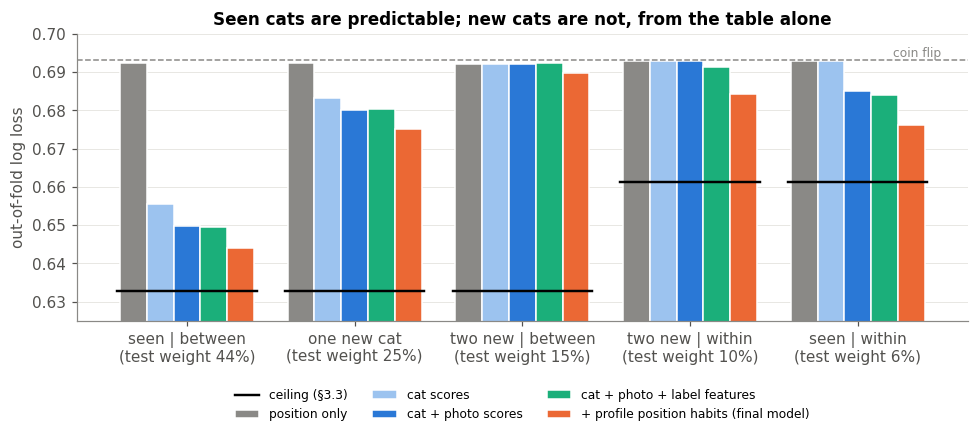

In [25]:
# @title
fig, ax = plt.subplots(figsize=(9, 4.2))
show = ["position only", "cat scores", "cat + photo scores", "cat + photo + label features",
        "+ profile position habits (final model)"]
cols = ["seen | between", "one new cat", "two new | between", "two new | within", "seen | within"]
x = np.arange(len(cols)); wdt = 0.16
palette = [GREY, "#9cc3ef", BLUE, AQUA, ORANGE]
for i, (m_, c_) in enumerate(zip(show, palette)):
    ax.bar(x + (i - 2) * wdt, ladder.loc[m_, cols], width=wdt, color=c_, label=m_, edgecolor="white", linewidth=1)
for j, c in enumerate(cols):
    ax.plot([j - 2.6 * wdt, j + 2.6 * wdt], [CEIL_CELL[c]] * 2, color="black", lw=1.6)
ax.plot([], [], color="black", lw=1.6, label="ceiling (§3.3)")
ax.axhline(np.log(2), color=GREY, ls="--", lw=1); ax.text(len(cols) - 0.5, np.log(2) + 0.0008, "coin flip", ha="right", color=GREY, fontsize=8)
ax.set_xticks(x, [f"{c}\n(test weight {W[c]:.0%})" for c in cols]); ax.set_ylim(0.625, 0.70)
ax.set_ylabel("out-of-fold log loss"); ax.grid(axis="x", visible=False)
ax.set_title("Seen cats are predictable; new cats are not, from the table alone")
ax.legend(fontsize=8, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.2))
save(fig, "3_2_ladder")

**Cat scores give by far the largest gain**: for pairs of seen cats the log loss falls from 0.692 to 0.656. Photo deviations then add a smaller gain wherever a photo is known, while the label features help only when two photos of the same cat are compared. Finally, left-side effects for the person's characteristics and profile improve every cell a little, because all test profiles appear in training.

**The final model reaches an estimated test log loss of 0.665, against 0.692 for position only and 0.637 for the ceiling, and thus closes about half (51%) of the gap.** However, this depends strongly on the cell: **81% of the gap is closed for pairs of seen cats, 29% with one new cat and only 4% with two new cats**, because the labels say nothing about how appealing a new cat is.

Even for seen cats, accuracy stays near 62%. This raises the question of what stops the model from doing better. Either people simply disagree (§3.3), or different people rank the cats differently, so that one shared model is not enough (§3.4).

## 3.3 How much do people agree?

If people often disagree about the same pair, part of the error cannot be avoided. Because each pair has only 1–4 votes, its true probability cannot be observed directly, so we model it. We assume that each pair $j$ has its own true probability $p_j$ that its first image is chosen, that the votes on the pair are independent choices with this probability, and that the $p_j$ of different pairs vary around 0.5. We then estimate by maximum likelihood how widely the $p_j$ vary, using pairs with at least two votes; a narrow spread around 0.5 means that people disagree. From this model we derive the **ceiling**, a non-standard quantity defined as the expected log loss of an imaginary model that knows every pair's true probability. No model can do better, because the remaining error comes from disagreement rather than from missing information. Since the ceiling relies on this model, we also check whether it reproduces how the votes on a pair split.

In [26]:
# @title
rows = []
for t in ["between_cats", "within_cat", "all"]:
    v = VOTES if t == "all" else VOTES[VOTES.type == t]
    a = fit_a(v) if t == "all" else A_HAT[t]
    c = ceiling(a)
    v2 = v[v.n >= 2]
    obs_agree = ((v2.k * (v2.k - 1) + (v2.n - v2.k) * (v2.n - v2.k - 1)).sum() / (v2.n * (v2.n - 1)).sum())
    # bootstrap CI for a (resample pairs)
    gen = np.random.default_rng(SEED); a_bs = []
    for _ in range(100):
        s_ = v2.iloc[gen.integers(0, len(v2), len(v2))]
        a_bs.append(fit_a(s_))
    rows.append({"pairs": t, "pairs with >=2 votes": len(v2), "a (MLE)": a,
                 "a 95% CI": f"{np.quantile(a_bs, .025):.2f}-{np.quantile(a_bs, .975):.2f}",
                 "SD of true p": np.sqrt(1 / (4 * (2 * a + 1))),
                 "agreement implied": (a + 1) / (2 * a + 1), "agreement observed": obs_agree,
                 "ceiling log loss": c["log loss"], "ceiling accuracy": c["accuracy"], "ceiling Brier": c["Brier"]})
ceil_tab = pd.DataFrame(rows).set_index("pairs"); display(ceil_tab)
A_ALL = fit_a(VOTES)
print(f"test-weighted ceiling (within/between mix of the test set): log loss {CEIL_CELL['TEST ESTIMATE']:.4f}")

,pairs with >=2 votes,a (MLE),a 95% CI,SD of true p,agreement implied,agreement observed,ceiling log loss,ceiling accuracy,ceiling Brier
pairs,,,,,,,,,
between_cats,6611,3.9168,3.45-4.54,0.1682,0.5566,0.5574,0.6329,0.6387,0.2215
within_cat,1016,7.7611,4.67-19.44,0.1230,0.5303,0.5305,0.6614,0.6006,0.2346
all,7627,4.1430,3.70-4.65,0.1641,0.5538,0.5547,0.6359,0.6351,0.2228


test-weighted ceiling (within/between mix of the test set): log loss 0.6374


In [27]:
# @title
# check of the disagreement model: how the votes on a pair split (unanimous or not), observed vs expected, for n = 2, 3, 4
gof = []
for t in ["between_cats", "within_cat"]:
    a = A_HAT[t]; chi_tot, df_tot = 0.0, 0
    for n in [2, 3, 4]:
        v = VOTES[(VOTES.type == t) & (VOTES.n == n)]
        split = np.minimum(v.k, n - v.k)                   # 0 = unanimous, ... (side-free)
        obs = split.value_counts().reindex(range(n // 2 + 1), fill_value=0)
        pk = stats.betabinom.pmf(np.arange(n + 1), n, a, a)
        exp_ = np.array([pk[s] + (pk[n - s] if n - s != s else 0) for s in range(n // 2 + 1)]) * len(v)
        chi2 = ((obs - exp_) ** 2 / exp_).sum(); chi_tot += chi2; df_tot += len(obs) - 1
        gof.append({"pairs": t, "votes per pair": n, "pairs (count)": len(v),
                    "observed: unanimous, 1 dissent, (2-2)": list(obs.values), "expected": list(np.round(exp_, 1))})
display(pd.DataFrame(gof).set_index(["pairs", "votes per pair"]))

pairs (count)  \
pairs        votes per pair                  
between_cats 2                        1162   
             3                        2533   
             4                        2916   
within_cat   2                         351   
             3                         475   
             4                         190   

                            observed: unanimous, 1 dissent, (2-2)  \
pairs        votes per pair                                         
between_cats 2                                         [620, 542]   
             3                                        [821, 1712]   
             4                                   [652, 1401, 863]   
within_cat   2                                         [186, 165]   
             3                                         [136, 339]   
             4                                       [38, 82, 70]   

                                           expected  
pairs        votes per pair                          
between_cats 2                       [646.8, 515.2]  
             3                      [848.3, 1684.7]  
             4               [623.5, 1412.3, 880.2]  
within_cat   2                       [186.1, 164.9]  
             3                       [140.3, 334.7]  
             4                   [32.6, 94.1, 63.3]

**The model fits the votes well** (the expected and observed numbers of unanimous and split pairs are very close), **and it shows that even a perfect model would be right only about 64% of the time.** For the test set's mix of comparisons, **the best possible log loss is 0.637**. To see how much of our own model's error is this unavoidable part, we split its log loss into the ceiling, which cannot be removed, and the remainder, which a better model could still remove.

,model log loss,position-only log loss,irreducible (ceiling),reducible left,irreducible share of model loss,reducible share removed by model
seen | between,0.6441,0.6924,0.6329,0.0113,98.2%,81.1%
seen | within,0.6762,0.6928,0.6614,0.0148,97.8%,52.9%
one new cat,0.6751,0.6924,0.6329,0.0423,93.7%,29.0%
two new | between,0.6897,0.6921,0.6329,0.0569,91.8%,4.0%
two new | within,0.6843,0.6928,0.6614,0.0230,96.6%,27.1%
TEST ESTIMATE,0.6646,0.6924,0.6374,0.0272,95.9%,50.5%


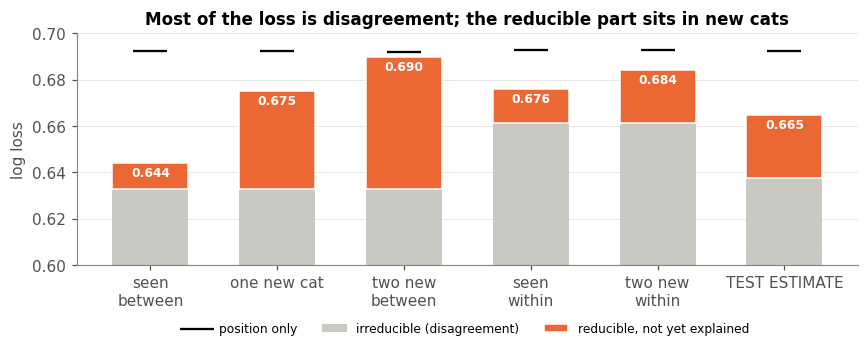

In [28]:
# @title
best = "+ profile position habits (final model)"
dec = pd.DataFrame({
    "model log loss": ladder.loc[best, CELLS + ["TEST ESTIMATE"]],
    "position-only log loss": ladder.loc["position only", CELLS + ["TEST ESTIMATE"]],
    "irreducible (ceiling)": pd.Series(CEIL_CELL)})
dec["reducible left"] = dec["model log loss"] - dec["irreducible (ceiling)"]
dec["irreducible share of model loss"] = dec["irreducible (ceiling)"] / dec["model log loss"]
dec["reducible share removed by model"] = (dec["position-only log loss"] - dec["model log loss"]) / (dec["position-only log loss"] - dec["irreducible (ceiling)"])
display(dec.style.format({c: "{:.4f}" for c in dec.columns[:4]} | {c: "{:.1%}" for c in dec.columns[4:]}))

fig, ax = plt.subplots(figsize=(8, 3.4))
order = ["seen | between", "one new cat", "two new | between", "seen | within", "two new | within", "TEST ESTIMATE"]
xx = np.arange(len(order))
ax.bar(xx, dec.loc[order, "irreducible (ceiling)"] - 0.6, bottom=0.6, color="#c9c8c3", width=0.6, label="irreducible (disagreement)")
ax.bar(xx, dec.loc[order, "reducible left"], bottom=dec.loc[order, "irreducible (ceiling)"], color=ORANGE, width=0.6,
       label="reducible, not yet explained", edgecolor="white", linewidth=1)
ax.scatter(xx, dec.loc[order, "position-only log loss"], marker="_", s=500, color="black", label="position only", zorder=3)
for i, c in enumerate(order):
    ax.text(i, dec.loc[c, "model log loss"] - 0.0015, f"{dec.loc[c, 'model log loss']:.3f}", ha="center", va="top",
            fontsize=8, color="white", fontweight="bold")
ax.set_xticks(xx, [o.replace(" | ", "\n") for o in order]); ax.set_ylim(0.6, 0.70); ax.set_ylabel("log loss")
ax.set_title("Most of the loss is disagreement; the reducible part sits in new cats")
ax.set_ylim(0.6, 0.70)
ax.legend(fontsize=8, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.2)); ax.grid(axis="x", visible=False)
save(fig, "3_3_decomposition")

**About 96% of the final model's log loss is disagreement between people, which no model can remove.** For pairs of seen cats only 0.011 could still be removed, so **the model is already close to the limit there**. By contrast, **about three quarters of the removable error lies with new cats**, where the labels give no information.

In short, **people agree only slightly more than chance (55.5%), and this disagreement explains most of the prediction error.** This conclusion, however, assumes that everyone ranks the cats in the same way. If different people liked different cats, a model that knew who was choosing could do better, which we test next.

## 3.4 Do all people rank the cats in the same way?

The Bradley–Terry model assumes one score per cat and photo, shared by everyone. According to the course notes, this can fail if the comparisons form too many cycles, if the judges are heterogeneous (different people have different tastes), or if the form of the model is wrong. We check these in turn. First, if preferences come from one score, cycles such as "A beats B, B beats C, C beats A" should not appear more often than chance allows, so we compare the observed share of such cycles among cats with simulations from the fitted model.

In [29]:
# @title
btw = train[train.within == 0]
cat_bt = BTModel(sc=full_t[0]).fit(btw)
cs, g_hat = cat_bt.scores()["cat"], cat_bt.model.intercept_[0]
# aggregate between-cat votes per unordered cat pair: wins of the alphabetically first cat
c1 = np.where(btw.a_cat < btw.b_cat, btw.a_cat, btw.b_cat); c2 = np.where(btw.a_cat < btw.b_cat, btw.b_cat, btw.a_cat)
first_won = np.where(btw.a_cat < btw.b_cat, btw.y, 1 - btw.y)
a_is_first = (btw.a_cat < btw.b_cat).to_numpy()
cp = pd.DataFrame({"c1": c1, "c2": c2, "w": first_won}).groupby(["c1", "c2"]).w.agg(["sum", "count"]).reset_index()
# all triangles of cats in which all three pairs were compared (fast search over the adjacency matrix)
cat_ids = np.array(sorted(set(cp.c1) | set(cp.c2))); pos_ = {c_: i for i, c_ in enumerate(cat_ids)}
A_ = np.zeros((len(cat_ids), len(cat_ids)), dtype=bool)
A_[cp.c1.map(pos_), cp.c2.map(pos_)] = True; A_ |= A_.T
tri_idx = []
for i in range(len(cat_ids)):
    for j in np.where(A_[i, i + 1:])[0] + i + 1:
        for k in np.where(A_[i, j + 1:] & A_[j, j + 1:])[0] + j + 1:
            tri_idx.append((i, j, k))
tri = cat_ids[np.array(tri_idx)]
key = {(a, b): i for i, (a, b) in enumerate(zip(cp.c1, cp.c2))}
def edge_idx(u, v): return np.array([key[(min(a, b), max(a, b))] for a, b in zip(u, v)])
e01, e12, e02 = edge_idx(tri[:, 0], tri[:, 1]), edge_idx(tri[:, 1], tri[:, 2]), edge_idx(tri[:, 0], tri[:, 2])
def orient(u, v):  # +1 if the edge is stored as (u, v) in (c1, c2) order
    return np.where(np.array([a < b for a, b in zip(u, v)]), 1, -1)
o01, o12, o02 = orient(tri[:, 0], tri[:, 1]), orient(tri[:, 1], tri[:, 2]), orient(tri[:, 0], tri[:, 2])

def cyclic_share(wins, counts, gen):
    dirn = np.sign(2 * wins - counts).astype(float)                 # +1: c1 wins majority
    ties = dirn == 0; dirn[ties] = gen.choice([-1, 1], ties.sum())
    d01, d12, d02 = dirn[e01] * o01, dirn[e12] * o12, dirn[e02] * o02  # +1: first-listed cat wins
    # cycle: 0>1, 1>2, 2>0  or the reverse
    return float(np.mean(((d01 > 0) & (d12 > 0) & (d02 < 0)) | ((d01 < 0) & (d12 < 0) & (d02 > 0))))

gen = np.random.default_rng(SEED)
obs_cyc = cyclic_share(cp["sum"].to_numpy(), cp["count"].to_numpy(), gen)
# simulate: each original row keeps its side assignment; P(A) from fitted scores + position
pa = special.expit(g_hat + btw.a_cat.map(cs).to_numpy() - btw.b_cat.map(cs).to_numpy())
grp = pd.DataFrame({"c1": c1, "c2": c2}).merge(cp[["c1", "c2"]].reset_index(), on=["c1", "c2"], how="left")["index"].to_numpy()
sims = []
for _ in range(100):
    ya = gen.random(len(pa)) < pa
    fw = np.where(a_is_first, ya, ~ya).astype(int)
    sims.append(cyclic_share(np.bincount(grp, fw, minlength=len(cp)), cp["count"].to_numpy(), gen))
sims = np.array(sims)
print(f"cat triangles with all three pairs compared: {len(tri):,}")
print(f"observed cyclic share {obs_cyc:.3f};  under BT: mean {sims.mean():.3f}, 95% range {np.quantile(sims, .025):.3f}-{np.quantile(sims, .975):.3f};"
      f"  one-sided p (observed >= simulated) = {np.mean(sims >= obs_cyc):.2f}")

cat triangles with all three pairs compared: 34,583
observed cyclic share 0.206;  under BT: mean 0.205, 95% range 0.200-0.211;  one-sided p (observed >= simulated) = 0.30


**There are no more cycles than expected**: 20.6% of cat triangles form a cycle, against 20.5% expected from the fitted model. Next, to test whether groups of people prefer different cats, we fit the cat scores separately in four splits of the people (women vs men, pet owners vs not, extraverts vs others, wanting a pet vs not). Since noise alone makes two groups differ somewhat, we compare each real split with random splits of the profiles of the same size.

In [30]:
# @title
comp = train[(train.within == 0) & (train.gender != "missing")].reset_index(drop=True)
SPLITS = {"women vs men": comp.gender == "woman",
          "current pet owners vs not": comp.pet_history == "current",
          "extraverts vs others": comp.mbti_ie == "E",
          "want a pet vs not": comp.future_pet == "yes"}
N_PERM = 20
prof_sizes = comp.groupby("profile").size()

def group_fit(g):
    # separate cat scores per group vs one shared set (both with a group-specific left-side effect)
    cg = comp.assign(_g=g.astype(float))
    shared = BTModel(sc=BOTH[0], extra=lambda d: d[["_g"]].to_numpy()).fit(cg)
    m1, m0 = BTModel(sc=BOTH[0]).fit(cg[g]), BTModel(sc=BOTH[0]).fit(cg[~g])
    ll_shared = -logloss_rows(cg.y.to_numpy(), shared.predict(cg)).sum()
    ll_sep = -logloss_rows(cg.y[g].to_numpy(), m1.predict(cg[g])).sum() - logloss_rows(cg.y[~g].to_numpy(), m0.predict(cg[~g])).sum()
    s1, s0 = m1.scores()["cat"], m0.scores()["cat"]; cc = s1.index.intersection(s0.index)
    return np.corrcoef(s1[cc], s0[cc])[0, 1], ll_sep - ll_shared

def random_profile_split(target, gen):
    order = gen.permutation(prof_sizes.index); cum = prof_sizes[order].cumsum().to_numpy()
    return comp.profile.isin(set(order[: np.searchsorted(cum, target) + 1])).to_numpy()

t1 = time.time(); het_rows = []
for name, g in SPLITS.items():
    g = g.to_numpy(); r_obs, gain = group_fit(g)
    gen = np.random.default_rng(SEED); null = np.array([group_fit(random_profile_split(g.sum(), gen)) for _ in range(N_PERM)])
    het_rows.append({"split": name, "rows": f"{g.sum():,} / {(~g).sum():,}",
                     "correlation of cat scores": r_obs, "correlation, random splits (mean)": null[:, 0].mean(),
                     "likelihood gain": gain, "likelihood gain, random splits (mean)": null[:, 1].mean(),
                     "share of random splits with a larger gain": np.mean(null[:, 1] >= gain)})
het = pd.DataFrame(het_rows).set_index("split")
display(het.style.format({c: "{:.3f}" for c in het.columns if c != "rows"}))
print(f"group comparison done in {time.time() - t1:.0f}s")

,rows,correlation of cat scores,"correlation, random splits (mean)",likelihood gain,"likelihood gain, random splits (mean)",share of random splits with a larger gain
split,,,,,,
women vs men,"9,136 / 12,298",0.802,0.828,140.934,119.396,0.050
current pet owners vs not,"7,512 / 13,922",0.794,0.817,131.745,120.614,0.200
extraverts vs others,"5,535 / 15,899",0.766,0.788,119.558,121.997,0.550
want a pet vs not,"15,042 / 6,392",0.796,0.791,123.046,116.345,0.300


group comparison done in 32s


**Different groups rank the cats in the same way**: the groups' scores agree almost as closely as for random splits, and separate rankings do not fit better than for random splits: between 5% and 55% of random splits give an even larger gain. Only the split by gender reaches the low end (5%), and with four splits tested, one value this low is not surprising. Individual tastes may still differ, but **not in any way linked to the recorded characteristics**, so they remain part of the disagreement in §3.3.

This raises a further question. If the person does not change which cat is preferred, why did the person's terms improve the predictions in §3.2? One explanation is that people differ in *how* they click rather than in *what* they like, so we compare the share of A across the 70 profiles with the range expected from noise.

,value
profiles,70.0000
variance of profile P(A),0.0044
expected variance from noise alone,0.0009
ratio observed / noise,4.8782
profiles outside noise range,0.2571
lowest profile P(A),0.2150
highest profile P(A),0.7027


,P(choose A),rows,A chosen
profile,,,
woman|current|occasionally|sometimes|no|I,0.2150,321,69
woman|current|past_regular|often|unsure|I,0.3944,322,127
man|current|current_regular|daily|unsure|I,0.3994,328,131
woman|past|occasionally|rarely|yes|I,0.6304,92,58
woman|never|past_regular|sometimes|yes|E,0.6400,100,64
woman|never|never|rarely|no|E,0.7027,296,208


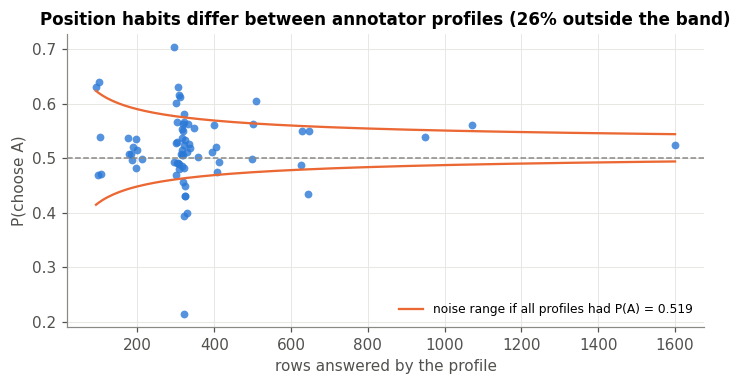

In [31]:
# @title
pf = train.groupby("profile").y.agg(["mean", "size", "sum"])
noise = (y.mean() * (1 - y.mean()) / pf["size"]).mean()
outside = ((pf["mean"] - y.mean()).abs() > 2 * np.sqrt(y.mean() * (1 - y.mean()) / pf["size"])).mean()
display(pd.DataFrame({"value": {
    "profiles": len(pf), "variance of profile P(A)": pf["mean"].var(), "expected variance from noise alone": noise,
    "ratio observed / noise": pf["mean"].var() / noise, "profiles outside noise range": outside,
    "lowest profile P(A)": pf["mean"].min(), "highest profile P(A)": pf["mean"].max()}}))
display(pf.sort_values("mean").iloc[[0, 1, 2, -3, -2, -1]].rename(columns={"mean": "P(choose A)", "size": "rows", "sum": "A chosen"}))

fig, ax = plt.subplots(figsize=(6.6, 3.6))
grid = np.linspace(pf["size"].min(), pf["size"].max(), 200); band = 2 * np.sqrt(y.mean() * (1 - y.mean()) / grid)
ax.plot(grid, y.mean() + band, color=ORANGE, lw=1.5, label="noise range if all profiles had P(A) = 0.519")
ax.plot(grid, y.mean() - band, color=ORANGE, lw=1.5)
ax.scatter(pf["size"], pf["mean"], s=26, color=BLUE, alpha=0.8, linewidths=0)
ax.axhline(0.5, color=GREY, lw=1, ls="--")
ax.set_xlabel("rows answered by the profile"); ax.set_ylabel("P(choose A)")
ax.set_title(f"Position habits differ between annotator profiles ({outside:.0%} outside the band)")
ax.legend(loc="lower right", fontsize=8)
save(fig, "3_4_profile_position")

**Clicking habits differ strongly between profiles**: the share of A varies 4.9 times more than noise allows, from 21% to 70%. Since many profiles are probably single people, this looks like a personal habit. Such a habit does not change the ranking of the cats, but it is predictable for people already seen, which explains why the profile terms help.

Finally, we check whether the logistic form misses any pattern. If it does not, predicted probabilities should match observed shares (calibration), and a shallow decision tree given the model's score together with all other variables should find nothing new.

calibration (pair-CV, full ID model): slope 0.926, intercept +0.005;  max |observed - predicted| over deciles 0.024


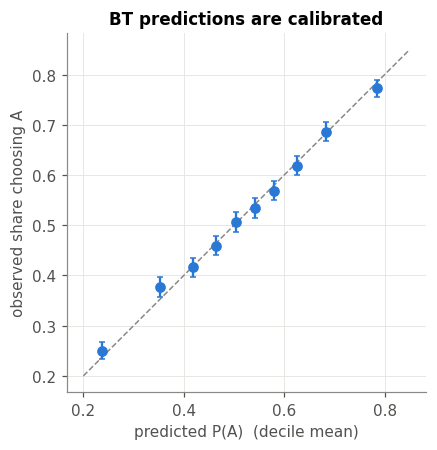

features used by the depth-3 tree (importance): {'bt_diff': 1.0}


In [32]:
# @title
def raw_features(df):
    X = pd.DataFrame({"first_first": (df.a_idx == 1).astype(int), "second_first": (df.b_idx == 1).astype(int),
                      "first_idx": df.a_idx, "second_idx": df.b_idx, "first_logn": np.log(df.a_n),
                      "second_logn": np.log(df.b_n), "within": df.within})
    for c in DEMO:
        for l in sorted(train[c].unique()):
            X[f"{c}={l}"] = (df[c] == l).astype(int)
    return X

p_full = OOF[best][0]
lg = special.logit(np.clip(p_full, 1e-6, 1 - 1e-6))
cal = LogisticRegression(C=1e6).fit(lg[:, None], y)
bins = pd.qcut(p_full, 10, duplicates="drop")
rel = pd.DataFrame({"p": p_full, "y": y}).groupby(bins, observed=True).agg(mean_pred=("p", "mean"), obs=("y", "mean"), n=("y", "size"))
rel["se"] = np.sqrt(rel.obs * (1 - rel.obs) / rel.n)
print(f"calibration (pair-CV, full ID model): slope {cal.coef_[0, 0]:.3f}, intercept {cal.intercept_[0]:+.3f};  "
      f"max |observed - predicted| over deciles {np.abs(rel.obs - rel.mean_pred).max():.3f}")

fig, ax = plt.subplots(figsize=(4.4, 4.2))
ax.plot([0.2, 0.85], [0.2, 0.85], color=GREY, ls="--", lw=1)
ax.errorbar(rel.mean_pred, rel.obs, yerr=1.96 * rel.se, fmt="o", color=BLUE, ms=6, capsize=2)
ax.set_xlabel("predicted P(A)  (decile mean)"); ax.set_ylabel("observed share choosing A")
ax.set_title("BT predictions are calibrated"); ax.set_aspect("equal")
save(fig, "3_4_calibration")

# shallow tree on mirrored data: BT logit (relative to first/second image) + everything else
d_ = train.assign(bt=lg - GAMMA)   # score difference without the position term
Xo = raw_features(d_); Xo["bt_diff"] = d_.bt; Xo["first_is_left"] = 1
Xm = Xo.copy()
for a_, b_ in [("first_first", "second_first"), ("first_idx", "second_idx"), ("first_logn", "second_logn")]:
    Xm[a_], Xm[b_] = Xo[b_], Xo[a_]
Xm["bt_diff"] = -Xo.bt_diff; Xm["first_is_left"] = 0
XX = pd.concat([Xo, Xm], ignore_index=True); yy = np.r_[y, 1 - y]
tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=500, random_state=SEED).fit(XX, yy)
imp = pd.Series(tree.feature_importances_, index=XX.columns); imp = imp[imp > 0].sort_values(ascending=False)
print("features used by the depth-3 tree (importance):", imp.round(3).to_dict())

**The predictions are well calibrated** (slope 0.93), **and the tree splits only on the model's score**, so nothing important is missing from the model.

Overall, **all groups of people rank the cats in the same way, so one shared appeal score for each cat and photo is enough.** People differ in individual taste, which is part of the unavoidable disagreement, and in clicking habits, which are predictable and already in the model.

The statistical analysis therefore shows that prediction is limited not by the form of the model but by **disagreement between people**, which no model can remove, and by **the lack of information about new cats**, which a score per label cannot provide. Since most of the removable error lies with new cats, the natural next step is to describe each photo by what it shows, such as whether the cat looks at the camera; any such model must be evaluated with cat-CV, because its purpose is to predict new cats. This is the topic of Section 5, while Section 4 first uses the present model to predict the test set.

---
# 4. Prediction and Checks

## 4.1 Test predictions

We fit the final model to all training rows and predict every test row. Pairs of seen cats use all parts of the model; a new cat gets score 0, so rows with two new cats rely only on the label features and the left-side effects.

,rows,mean_prob_a,sd,min,max,share_choice_A
cell,,,,,,
seen | between,2743,0.525,0.165,0.040,0.966,0.573
seen | within,369,0.527,0.093,0.191,0.733,0.650
one new cat,1556,0.520,0.145,0.123,0.918,0.552
two new | between,926,0.522,0.061,0.200,0.697,0.657
two new | within,630,0.522,0.068,0.200,0.719,0.635
all test rows,6224,0.523,0.137,0.040,0.966,0.591


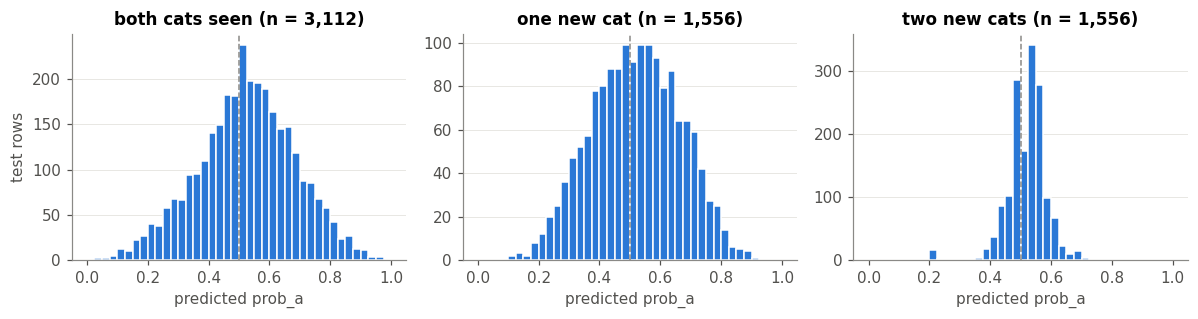

In [33]:
# @title
final = BTModel(*BOTH, feats=True, groups=True, prof=PROF).fit(train)
test["prob_a"] = final.predict(test)
test["choice"] = np.where(test.prob_a >= 0.5, "A", "B")

summ = test.groupby("cell").agg(rows=("prob_a", "size"), mean_prob_a=("prob_a", "mean"), sd=("prob_a", "std"),
                                min=("prob_a", "min"), max=("prob_a", "max"),
                                share_choice_A=("choice", lambda s: (s == "A").mean())).reindex(CELLS)
summ.loc["all test rows"] = [len(test), test.prob_a.mean(), test.prob_a.std(), test.prob_a.min(), test.prob_a.max(),
                             (test.choice == "A").mean()]
display(summ.style.format({"rows": "{:.0f}"} | {c: "{:.3f}" for c in summ.columns if c != "rows"}))

fig, axes = plt.subplots(1, 3, figsize=(11, 3), sharex=True)
for ax, cells_, title in zip(axes, [["seen | between", "seen | within"], ["one new cat"], ["two new | between", "two new | within"]],
                             ["both cats seen", "one new cat", "two new cats"]):
    v = test.loc[test.cell.isin(cells_), "prob_a"]
    ax.hist(v, bins=np.linspace(0, 1, 41), color=BLUE, edgecolor="white")
    ax.axvline(0.5, color=GREY, ls="--", lw=1)
    ax.set_title(f"{title} (n = {len(v):,})"); ax.set_xlabel("predicted prob_a"); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("test rows")
save(fig, "4_1_prob_distribution")

**The predictions are spread out where the model knows the cats and stay close to 0.5 where it does not.** About 59% of the predicted choices are A, slightly more than the 52% base rate, because the left-side effect pushes uncertain cases just above 0.5.

## 4.2 Expected performance and robustness

The expected test performance is the cross-validated result of the final model, with a 95% confidence interval from a bootstrap that resamples whole pairs.

In [34]:
# @title
best = "+ profile position habits (final model)"
P_PAIR, P_CAT = OOF[best]
def per_cell(p_pair, p_cat, cp=None, cc=None, fn=None):
    cp = cell_pair if cp is None else cp; cc = cell_cat if cc is None else cc; out = {}
    for c in CELLS:
        m_ = (cp == c) if c.startswith("seen") else (cc == c); p_ = p_pair if c.startswith("seen") else p_cat
        out[c] = fn(y[m_], p_[m_]) if fn else logloss_rows(y[m_], p_[m_]).mean()
    out["TEST ESTIMATE"] = sum(W[c] * out[c] for c in CELLS)
    return out
acc = lambda y_, p: np.mean((p >= 0.5) == y_)
est_ll, est_acc = per_cell(P_PAIR, P_CAT), per_cell(P_PAIR, P_CAT, fn=acc)
pos_ll = per_cell(*OOF["position only"])
ceil_acc = {c: CEIL["within_cat" if "within" in c else "between_cats"]["accuracy"] for c in CELLS}

gen = np.random.default_rng(SEED); Bn = 2000; draws = np.zeros(Bn)
for c in CELLS:
    m_ = (cell_pair == c) if c.startswith("seen") else (cell_cat == c); p_ = P_PAIR if c.startswith("seen") else P_CAT
    g = pd.DataFrame({"l": logloss_rows(y[m_], p_[m_]), "g": train.pair_u.to_numpy()[m_]}).groupby("g").l.agg(["sum", "count"])
    idx = gen.integers(0, len(g), (Bn, len(g)))
    draws += W[c] * g["sum"].to_numpy()[idx].sum(1) / g["count"].to_numpy()[idx].sum(1)
lo, hi = np.quantile(draws, [0.025, 0.975])

perf = pd.DataFrame({"test rows": test.cell.value_counts().reindex(CELLS), "expected log loss": pd.Series(est_ll),
                     "expected accuracy": pd.Series(est_acc), "position only": pd.Series(pos_ll),
                     "ceiling log loss": pd.Series(CEIL_CELL), "ceiling accuracy": pd.Series(ceil_acc)}).reindex(CELLS + ["TEST ESTIMATE"])
perf.loc["TEST ESTIMATE", "test rows"] = len(test)
perf.loc["TEST ESTIMATE", "ceiling accuracy"] = sum(W[c] * ceil_acc[c] for c in CELLS)
perf["gap closed"] = (perf["position only"] - perf["expected log loss"]) / (perf["position only"] - perf["ceiling log loss"])
display(perf.style.format({"test rows": "{:.0f}", "gap closed": "{:.0%}"} |
                          {c: "{:.4f}" for c in perf.columns if c not in ["test rows", "gap closed"]}))
print(f"expected test log loss {est_ll['TEST ESTIMATE']:.4f} (95% CI {lo:.4f}-{hi:.4f}); expected accuracy {est_acc['TEST ESTIMATE']:.3f}")

,test rows,expected log loss,expected accuracy,position only,ceiling log loss,ceiling accuracy,gap closed
seen | between,2743,0.6441,0.6242,0.6924,0.6329,0.6387,81%
seen | within,369,0.6762,0.5764,0.6928,0.6614,0.6006,53%
one new cat,1556,0.6751,0.5856,0.6924,0.6329,0.6387,29%
two new | between,926,0.6897,0.5285,0.6921,0.6329,0.6387,4%
two new | within,630,0.6843,0.5571,0.6928,0.6614,0.6006,27%
TEST ESTIMATE,6224,0.6646,0.5907,0.6924,0.6374,0.6326,51%


expected test log loss 0.6646 (95% CI 0.6623-0.6671); expected accuracy 0.591


**Expected test performance: log loss 0.665 (95% CI 0.662–0.667) and accuracy about 59%**, ranging from 62% for pairs of seen cats (close to the 64% ceiling) to 53% for two new cats. To check that these predictions do not depend on arbitrary choices, we change one choice at a time and repeat the estimate.

In [35]:
# @title
def fit_variant(d_tr, variant):
    if variant is None:         return BTModel(*BOTH, feats=True, groups=True, prof=PROF).fit(d_tr)
    if variant == "no missing": return BTModel(*BOTH, feats=True, groups=True, prof=PROF).fit(d_tr[d_tr.gender != "missing"])
    if variant == "pair weights":
        n_pair = d_tr.pair_u.map(d_tr.pair_u.value_counts()).to_numpy()
        return BTModel(*BOTH, feats=True, groups=True, prof=PROF).fit(d_tr, w=n_pair.mean() / n_pair)
    if variant == "no profile": return BTModel(*BOTH, feats=True, groups=True).fit(d_tr)

def cv_estimate(variant=None, seed=SEED):
    pf, cf = pair_folds(train, 5, seed), cat_folds(train, 5, seed)
    pp, pc = np.full(len(train), np.nan), np.full(len(train), np.nan)
    cc = np.empty(len(train), dtype=object)
    for tr_i, va_i in pf: pp[va_i] = fit_variant(train.iloc[tr_i], variant).predict(train.iloc[va_i])
    for tr_i, va_i, held in cf:
        pc[va_i] = fit_variant(train.iloc[tr_i], variant).predict(train.iloc[va_i])
        h, w = held[va_i], train.within.to_numpy()[va_i]
        cc[va_i] = np.where(h == 1, "one new cat", np.where(w == 1, "two new | within", "two new | between"))
    return per_cell(pp, pc, cc=cc)

t1 = time.time(); rob = []
for label, variant in [("main model", None), ("without rows missing person info", "no missing"),
                       ("equal weight per pair", "pair weights"), ("without profile terms", "no profile")]:
    est = est_ll["TEST ESTIMATE"] if variant is None else cv_estimate(variant)["TEST ESTIMATE"]
    p_test = test.prob_a.to_numpy() if variant is None else fit_variant(train, variant).predict(test)
    rob.append({"variant": label, "CV test estimate (log loss)": est,
                "largest change in prob_a": np.abs(p_test - test.prob_a).max(),
                "correlation with main": np.corrcoef(p_test, test.prob_a)[0, 1],
                "choices flipped": np.mean((p_test >= 0.5) != (test.prob_a >= 0.5))})
display(pd.DataFrame(rob).set_index("variant").style.format("{:.4f}"))

seeds = pd.DataFrame([est_ll] + [cv_estimate(seed=s_) for s_ in [1, 2]], index=["seed 2026", "seed 1", "seed 2"])
seeds.loc["SD across seeds"] = seeds.std()
display(seeds.style.format("{:.4f}"))
print(f"robustness checks done in {time.time() - t1:.0f}s")

,CV test estimate (log loss),largest change in prob_a,correlation with main,choices flipped
variant,,,,
main model,0.6646,0.0000,1.0000,0.0000
without rows missing person info,0.6649,0.1333,0.9927,0.0220
equal weight per pair,0.6655,0.0924,0.9885,0.0549
without profile terms,0.6675,0.2072,0.9490,0.1189


,seen | between,seen | within,one new cat,two new | between,two new | within,TEST ESTIMATE
seed 2026,0.6441,0.6762,0.6751,0.6897,0.6843,0.6646
seed 1,0.6442,0.6768,0.6771,0.6912,0.6842,0.6654
seed 2,0.6453,0.6794,0.6757,0.6858,0.6830,0.6648
SD across seeds,0.0007,0.0017,0.0010,0.0028,0.0007,0.0004


robustness checks done in 59s


**The predictions are robust.** Dropping the rows without information about the person, giving every pair equal weight or changing the random folds moves the estimate by less than 0.001. Only removing the profile terms makes it worse, which confirms that they should be kept.

## 4.3 Output file

Finally, `prob_a` and `choice` are written into a copy of `test.csv`, which is then read back and checked.

In [36]:
# @title
raw_test = pd.read_csv(DATA_DIR / "test.csv", encoding="utf-8-sig", dtype=str, keep_default_na=False)
out = raw_test.copy()
assert (out.test_row_id.to_numpy() == test.test_row_id.to_numpy()).all(), "row order changed"
out["prob_a"] = test.prob_a.round(6).map(lambda v: f"{v:.6f}")
out["choice"] = test.choice
OUT_FILE = Path("test_prediction.csv")
out.to_csv(OUT_FILE, index=False)

# validation: re-read the written file and check it against the original
chk = pd.read_csv(OUT_FILE, dtype=str, keep_default_na=False)
pa = chk.prob_a.astype(float)
other_cols = [c for c in raw_test.columns if c not in ("prob_a", "choice")]
checks = pd.Series({
    "rows (expected 6,224)": len(chk),
    "columns identical to test.csv": list(chk.columns) == list(raw_test.columns),
    "row order / test_row_id unchanged": (chk.test_row_id == raw_test.test_row_id).all(),
    "all other fields unchanged": chk[other_cols].equals(raw_test[other_cols]),
    "prob_a missing": int((chk.prob_a == "").sum()),
    "prob_a within [0, 1]": bool(((pa >= 0) & (pa <= 1)).all()),
    "choice only A/B": set(chk.choice) <= {"A", "B"},
    "choice == A iff prob_a >= 0.5": bool(((pa >= 0.5) == (chk.choice == "A")).all()),
}, name="check")
display(checks.to_frame())
assert checks.iloc[1:4].all() and checks.iloc[5:].all() and checks.iloc[0] == 6224 and checks.iloc[4] == 0
display(chk.head())
print("written:", OUT_FILE.resolve())

,check
"rows (expected 6,224)",6224
columns identical to test.csv,True
row order / test_row_id unchanged,True
all other fields unchanged,True
prob_a missing,0
"prob_a within [0, 1]",True
choice only A/B,True
choice == A iff prob_a >= 0.5,True


,test_row_id,a_cat,b_cat,a_image,b_image,choice,prob_a,comparison_type,gender,pet_history,pet_care,pet_contact,future_pet,mbti_ie
0,T000001,cat_001493,cat_002269,cat_001493/cat_001493_0004.jpg,cat_002269/cat_002269_0006.jpg,A,0.692301,between_cats,man,past,past_regular,sometimes,unsure,unknown
1,T000002,cat_000251,cat_002442,cat_000251/cat_000251_0003.jpg,cat_002442/cat_002442_0004.jpg,A,0.567558,between_cats,woman,never,occasionally,rarely,yes,I
2,T000003,cat_000694,cat_004987,cat_000694/cat_000694_0004.jpg,cat_004987/cat_004987_0001.jpg,B,0.399775,between_cats,woman,never,never,rarely,no,E
3,T000004,cat_005018,cat_002394,cat_005018/cat_005018_0005.jpg,cat_002394/cat_002394_0001.jpg,B,0.439987,between_cats,man,past,past_regular,sometimes,unsure,unknown
4,T000005,cat_000298,cat_000015,cat_000298/cat_000298_0002.jpg,cat_000015/cat_000015_0004.jpg,B,0.408697,between_cats,man,past,past_regular,sometimes,unsure,unknown


written: /content/test_prediction.csv


---
# 5. Image Features

…

---
# 6. Conclusion

## 6.1 Summary

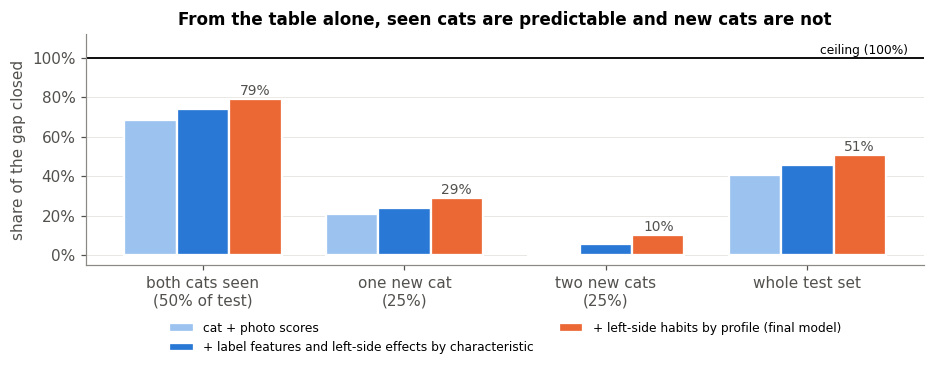

total run time: 225s


In [37]:
# @title
lad = ladder.drop(index=["coin flip"])
groups = {"both cats seen\n(50% of test)": ["seen | between", "seen | within"], "one new cat\n(25%)": ["one new cat"],
          "two new cats\n(25%)": ["two new | between", "two new | within"], "whole test set": None}
def grp_gap(row, cells_):
    if cells_ is None:
        return (lad.loc["position only", "TEST ESTIMATE"] - lad.loc[row, "TEST ESTIMATE"]) / \
               (lad.loc["position only", "TEST ESTIMATE"] - lad.loc["ceiling (disagreement)", "TEST ESTIMATE"])
    w_ = W[cells_] / W[cells_].sum()
    num = sum(w_[c] * (lad.loc["position only", c] - lad.loc[row, c]) for c in cells_)
    den = sum(w_[c] * (lad.loc["position only", c] - lad.loc["ceiling (disagreement)", c]) for c in cells_)
    return num / den
rows_ = ["cat + photo scores", "+ annotator position terms", "+ profile position habits (final model)"]
labels_ = ["cat + photo scores", "+ label features and left-side effects by characteristic", "+ left-side habits by profile (final model)"]
cols_ = ["#9cc3ef", BLUE, ORANGE]
fig, ax = plt.subplots(figsize=(8.6, 3.6)); xx = np.arange(len(groups)); wd = 0.26
for i, (r, lab, c_) in enumerate(zip(rows_, labels_, cols_)):
    vals = [grp_gap(r, cl) for cl in groups.values()]
    ax.bar(xx + (i - 1) * wd, vals, width=wd, color=c_, label=lab, edgecolor="white", linewidth=1.5)
    if i == 2:
        for x_, v_ in zip(xx, vals): ax.text(x_ + wd, v_ + 0.02, f"{v_:.0%}", ha="center", fontsize=9, color=INK)
ax.axhline(1, color="black", lw=1.2); ax.text(len(groups) - 0.5, 1.02, "ceiling (100%)", ha="right", fontsize=8)
ax.set_xticks(xx, list(groups)); ax.set_ylim(-0.05, 1.12); ax.set_ylabel("share of the gap closed")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("From the table alone, seen cats are predictable and new cats are not")
ax.legend(fontsize=8, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.2)); ax.grid(axis="x", visible=False)
save(fig, "6_1_gap_closed")
print(f"total run time: {time.time() - T0:.0f}s")

**The choices are only moderately predictable.** From the training table alone, the expected test log loss is 0.665 and the accuracy about 59%, which is half of the way from guessing (50%) to the best possible (about 63%). For pairs of seen cats the model gets about 80% of the way, mainly through which cat is shown, whereas for new cats it gets almost nowhere.

**Two things limit predictability, while the model form does not.** The largest limit is **disagreement between people**: two people agree on a pair only 55.5% of the time, and this explains about 96% of the model's error. The largest removable limit is **the lack of information about new cats**. By contrast, one shared ranking describes everyone's choices, since groups of people prefer the same cats and differ only in clicking habits, which the model already uses. Finally, a validation design that matches the test set avoids data leakage; a random split would have overstated the accuracy (62% instead of 59%).

## 6.2 Findings and interpretation

| Statement | Status |
|---|---|
| Expected test log loss ≈ 0.665, accuracy ≈ 59% | finding (cross-validated estimate) |
| The best possible is about 0.637 / 63% | finding, based on the model of disagreement in §3.3 |
| Which cat is shown is the main driver of choices | finding |
| Groups of people share one ranking; profiles differ in clicking habits | finding |
| These habits belong to individual people | interpretation (profiles are not people) |
| Photo 1 is a "cover photo" chosen by the dataset creators | speculation |

## 6.3 Limitations and next steps

The main limitations are that there is no person ID, so individual tastes cannot be modelled; that each pair has only 1–4 votes, so the ceiling depends on the Beta assumption; and that cross-validation estimates rather than measures the test result. **The natural next step is to add information about what the photos show, which is where most of the removable error lies.**